# Benchmark (RDD) Models


## 1. Environment

In [5]:
import csv
import gc
import json
import sys
import time
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple

import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.image as mpimg
import numpy as np
import torch
import torch.nn as nn
import torchvision.ops
import yaml

from ultralytics import YOLO
from ultralytics.nn import tasks, modules
from ultralytics.nn.modules import Conv, Detect
from ultralytics.utils.torch_utils import get_flops

# -------------------------------------------------------------
# Dataset Constants (P25 RDD Dataset - 4 Classes)
# -------------------------------------------------------------
CLASS_NAMES = ['D00', 'D10', 'D20', 'D40']
CLASS_LABELS = {
    'D00': 'Longitudinal Crack',
    'D10': 'Transverse Crack',
    'D20': 'Alligator Crack',
    'D40': 'Pothole',
}
CLASS_COLORS = {
    'D00': (46, 204, 113),   # Green (RGB)
    'D10': (52, 152, 219),   # Blue (RGB)
    'D20': (231, 76, 60),    # Red (RGB)
    'D40': (243, 156, 18),   # Amber/Orange (RGB)
}

# -------------------------------------------------------------
# P26 Custom Architectural Modules (YOLO-DGVG Methodology)
# Supports native CPU and CUDA GPU execution
# -------------------------------------------------------------
class DeformConv2d(nn.Module):
    def __init__(self, inc: int, outc: int, kernel_size: int = 3, padding: int = 1, stride: int = 1, bias: Optional[bool] = None):
        super().__init__()
        self.stride = stride
        self.padding = padding
        self.conv_offset = nn.Conv2d(inc, 3 * kernel_size * kernel_size, kernel_size=kernel_size, stride=stride, padding=padding, bias=True)
        nn.init.constant_(self.conv_offset.weight, 0.0)
        nn.init.constant_(self.conv_offset.bias, 0.0)
        self.weight = nn.Parameter(torch.empty(outc, inc, kernel_size, kernel_size))
        nn.init.kaiming_uniform_(self.weight, a=1)
        if bias:
            self.bias = nn.Parameter(torch.zeros(outc))
        else:
            self.register_parameter('bias', None)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        orig_dtype = x.dtype
        x_f = x.float().contiguous(memory_format=torch.contiguous_format)
        out = self.conv_offset(x_f)
        o1, o2, mask = torch.chunk(out, 3, dim=1)
        offset = torch.cat((o1, o2), dim=1).contiguous(memory_format=torch.contiguous_format)
        offset = torch.nan_to_num(offset, nan=0.0, posinf=10.0, neginf=-10.0)
        mask = torch.nan_to_num(torch.sigmoid(mask), nan=0.5).contiguous(memory_format=torch.contiguous_format)
        w_f = self.weight.float().contiguous(memory_format=torch.contiguous_format)
        b_f = self.bias.float().contiguous(memory_format=torch.contiguous_format) if self.bias is not None else None
        try:
            res = torchvision.ops.deform_conv2d(
                input=x_f, offset=offset, weight=w_f, bias=b_f,
                stride=(self.stride, self.stride), padding=(self.padding, self.padding), mask=mask
            )
        except Exception:
            res = nn.functional.conv2d(x_f, w_f, b_f, stride=self.stride, padding=self.padding)
        return res.to(orig_dtype)

class Bottleneck_DCNv2(nn.Module):
    def __init__(self, c1: int, c2: int, shortcut: bool = True, g: int = 1, k: Tuple[int, int] = (3, 3), e: float = 0.5):
        super().__init__()
        c_ = int(c2 * e)
        self.cv1 = Conv(c1, c_, k[0], 1)
        self.dcn = DeformConv2d(c_, c2, k[1], 1, padding=k[1] // 2)
        self.bn = nn.BatchNorm2d(c2)
        self.act = nn.SiLU()
        self.add = shortcut and c1 == c2

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = self.act(self.bn(self.dcn(self.cv1(x))))
        return x + out if self.add else out

class C2f_DCNv2(nn.Module):
    def __init__(self, c1: int, c2: int, n: int = 1, shortcut: bool = False, g: int = 1, e: float = 0.5):
        super().__init__()
        self.c = int(c2 * e)
        self.cv1 = Conv(c1, 2 * self.c, 1, 1)
        self.cv2 = Conv((2 + n) * self.c, c2, 1)
        self.m = nn.ModuleList(Bottleneck_DCNv2(self.c, self.c, shortcut, g, k=(3, 3), e=1.0) for _ in range(n))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        y = list(self.cv1(x).chunk(2, 1))
        y.extend(m(y[-1]) for m in self.m)
        return self.cv2(torch.cat(y, 1))

class GSConv(nn.Module):
    def __init__(self, c1: int, c2: int, k: int = 1, s: int = 1, g: int = 1, act: bool = True):
        super().__init__()
        c_ = c2 // 2
        self.cv1 = Conv(c1, c_, k, s, None, g, act=act)
        self.cv2 = Conv(c_, c_, 5, 1, None, c_, act=act)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x1 = self.cv1(x)
        x2 = self.cv2(x1)
        b, c, h, w = x1.shape
        out = torch.cat((x1, x2), dim=1)
        out = out.view(b, 2, c, h, w).transpose(1, 2).contiguous().view(b, c * 2, h, w)
        return out

class GSBottleneck(nn.Module):
    def __init__(self, c1: int, c2: int, k: int = 3, s: int = 1, e: float = 0.5):
        super().__init__()
        c_ = int(c2 * e)
        self.conv1 = GSConv(c1, c_, 1, 1)
        self.conv2 = GSConv(c_, c2, 3, 1)
        self.shortcut = c1 == c2

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x + self.conv2(self.conv1(x)) if self.shortcut else self.conv2(self.conv1(x))

class VoVGSCSP(nn.Module):
    def __init__(self, c1: int, c2: int, n: int = 1, shortcut: bool = True, g: int = 1, e: float = 0.5):
        super().__init__()
        c_ = int(c2 * e)
        self.cv1 = Conv(c1, c_, 1, 1)
        self.cv2 = Conv(2 * c_, c2, 1, 1)
        self.m = nn.Sequential(*(GSBottleneck(c_, c_, e=1.0) for _ in range(n)))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x1 = self.cv1(x)
        return self.cv2(torch.cat((self.m(x1), x1), dim=1))

class GCHDetect(Detect):
    def __init__(self, nc: int = 80, reg_max: int = 16, end2end: bool = False, ch: Tuple[int, ...] = ()):
        super().__init__(nc, reg_max, end2end, ch)
        c_mid = max(16, ch[0] // 4, self.reg_max * 4)
        g = 4
        self.shared = nn.ModuleList(
            nn.Sequential(
                Conv(x, c_mid, 3, g=min(g, x, c_mid)),
                Conv(c_mid, c_mid, 3, g=min(g, c_mid)),
            ) for x in ch
        )
        self.cv2 = nn.ModuleList(nn.Sequential(nn.Conv2d(c_mid, 4 * self.reg_max, 1)) for _ in ch)
        self.cv3 = nn.ModuleList(nn.Sequential(nn.Conv2d(c_mid, self.nc, 1)) for _ in ch)

    def forward_head(self, x: List[torch.Tensor], box_head=None, cls_head=None) -> Dict[str, Any]:
        bs = x[0].shape[0]
        feats = [self.shared[i](x[i]) for i in range(self.nl)]
        boxes = torch.cat([self.cv2[i](feats[i]).view(bs, 4 * self.reg_max, -1) for i in range(self.nl)], dim=-1)
        scores = torch.cat([self.cv3[i](feats[i]).view(bs, self.nc, -1) for i in range(self.nl)], dim=-1)
        return {'boxes': boxes, 'scores': scores, 'feats': x}

def register_p26_modules():
    p26_classes = [DeformConv2d, Bottleneck_DCNv2, C2f_DCNv2, GSConv, GSBottleneck, VoVGSCSP, GCHDetect]
    main_mod = sys.modules.get('__main__')
    for cls in p26_classes:
        if main_mod:
            setattr(main_mod, cls.__name__, cls)
        setattr(tasks, cls.__name__, cls)
        setattr(modules, cls.__name__, cls)
        if hasattr(tasks, 'torch') and hasattr(tasks.torch, 'nn'):
            setattr(tasks.torch.nn, cls.__name__, cls)
    if hasattr(torch, 'serialization') and hasattr(torch.serialization, 'add_safe_globals'):
        try:
            torch.serialization.add_safe_globals(p26_classes)
        except Exception:
            pass

register_p26_modules()

def clear_hardware_cache():
    '''Release GPU and MPS unified memory.'''
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    if hasattr(torch, 'mps') and torch.backends.mps.is_available():
        try:
            torch.mps.empty_cache()
        except Exception:
            pass

# Automatic compute device selection
if torch.cuda.is_available():
    DEVICE = 'cuda:0'
elif torch.backends.mps.is_available():
    DEVICE = 'mps'
else:
    DEVICE = 'cpu'

# Multi-platform path resolver for Local, Kaggle, or Google Colab
def resolve_path(name: str, candidate_dirs: List[Path]) -> Path:
    for base in candidate_dirs:
        candidate = base / name
        if candidate.exists():
            return candidate
    return candidate_dirs[0] / name

_cwd = Path('.').resolve()
if (_cwd / 'model').exists() and (_cwd / 'dataset').exists():
    PROJECT_ROOT = _cwd
elif (_cwd.parent / 'model').exists() and (_cwd.parent / 'dataset').exists():
    PROJECT_ROOT = _cwd.parent
else:
    PROJECT_ROOT = _cwd

BENCHMARK_DIR = PROJECT_ROOT / 'benchmark'
BENCHMARK_DIR.mkdir(parents=True, exist_ok=True)

search_bases = [
    PROJECT_ROOT,
    _cwd,
    Path('/kaggle/working'),
    Path('/kaggle/input/ail-rdd'),
    Path('/kaggle/input/road-damage-dataset'),
]
MODEL_DIR = resolve_path('model', search_bases)
DATASET_DIR = resolve_path('dataset', search_bases)

# Locate model checkpoints
target_models = sorted(list(MODEL_DIR.glob('*.pt')))

print(f'Compute Device: {DEVICE}')
print(f'Project Root:   {PROJECT_ROOT}')
print(f'Model Dir:      {MODEL_DIR} (Found {len(target_models)} models)')
print(f'Dataset Dir:    {DATASET_DIR}')
print('P26 modules registered successfully.')


Compute Device: cpu
Project Root:   /Users/trietnguyen/Documents/AIL-RDD
Model Dir:      /Users/trietnguyen/Documents/AIL-RDD/model (Found 4 models)
Dataset Dir:    /Users/trietnguyen/Documents/AIL-RDD/dataset
P26 modules registered successfully.


## 2. Model Architecture & Pipeline


In [6]:
class YOLOv26nPipeline:
    '''End-to-end inference pipeline for yolov26n_best.pt.'''
    def __init__(self, model_path: Path, device: str = 'cpu'):
        self.model_path = Path(model_path)
        self.device = device
        if not self.model_path.exists():
            raise FileNotFoundError(f'Checkpoint not found: {self.model_path}')
        self.model = YOLO(str(self.model_path))

    def predict(
        self,
        image_input: Any,
        conf_threshold: float = 0.25,
        iou_threshold: float = 0.45,
        imgsz: int = 640,
    ) -> Dict[str, Any]:
        '''Execute inference and benchmark per-stage execution latency.'''
        start_time = time.perf_counter()
        results = self.model.predict(
            source=image_input,
            conf=conf_threshold,
            iou=iou_threshold,
            imgsz=imgsz,
            device=self.device,
            verbose=False,
        )
        total_time_ms = (time.perf_counter() - start_time) * 1000.0
        res = results[0]
        speed_info = res.speed  # preprocess, inference, postprocess

        detections = []
        if res.boxes is not None and len(res.boxes) > 0:
            boxes = res.boxes.xyxy.cpu().numpy()
            confs = res.boxes.conf.cpu().numpy()
            classes = res.boxes.cls.cpu().numpy().astype(int)
            for box, conf, cls_id in zip(boxes, confs, classes):
                cls_name = CLASS_NAMES[cls_id] if cls_id < len(CLASS_NAMES) else f'cls_{cls_id}'
                detections.append({
                    'class_id': int(cls_id),
                    'class_name': cls_name,
                    'description': CLASS_LABELS.get(cls_name, ''),
                    'confidence': float(conf),
                    'bbox': [float(x) for x in box],
                })

        return {
            'orig_image': res.orig_img,
            'detections': detections,
            'count': len(detections),
            'speed': speed_info,
            'total_time_ms': total_time_ms,
            'fps': round(1000.0 / total_time_ms, 1) if total_time_ms > 0 else 0.0,
        }

    def visualize_prediction(
        self,
        pred_result: Dict[str, Any],
        title: str = 'YOLOv26n Detection Result',
        figsize: Tuple[int, int] = (10, 8),
    ) -> None:
        '''Render annotated bounding boxes with class colors and latency header.'''
        img_bgr = pred_result['orig_image'].copy()
        for det in pred_result['detections']:
            x1, y1, x2, y2 = [int(v) for v in det['bbox']]
            cname = det['class_name']
            conf = det['confidence']
            rgb_color = CLASS_COLORS.get(cname, (0, 255, 0))
            bgr_color = (rgb_color[2], rgb_color[1], rgb_color[0])
            cv2.rectangle(img_bgr, (x1, y1), (x2, y2), bgr_color, 2)
            label_text = f'{cname}: {conf:.2f}'
            (tw, th), _ = cv2.getTextSize(label_text, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 1)
            cv2.rectangle(img_bgr, (x1, max(0, y1 - 22)), (x1 + tw + 4, max(0, y1)), bgr_color, -1)
            cv2.putText(img_bgr, label_text, (x1 + 2, max(0, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1, cv2.LINE_AA)

        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=figsize)
        plt.imshow(img_rgb)
        speed_str = f'Inference: {pred_result["speed"].get("inference", 0.0):.1f}ms | Total: {pred_result["total_time_ms"]:.1f}ms ({pred_result["fps"]} FPS)'
        plt.title(f'{title} ({pred_result["count"]} detections)\n{speed_str}', fontsize=12)
        plt.axis('off')
        plt.tight_layout()
        plt.show()

# Instantiate YOLOv26n pipeline
yolov26n_path = MODEL_DIR / 'yolov26n_best.pt'
if yolov26n_path.exists():
    pipeline = YOLOv26nPipeline(yolov26n_path, device=DEVICE)
    print(f'YOLOv26n pipeline initialized successfully with {yolov26n_path.name}')
else:
    print(f'Warning: Checkpoint not found at {yolov26n_path}')


YOLOv26n pipeline initialized successfully with yolov26n_best.pt


## 3. Unified Benchmark Engine

In [7]:
# -------------------------------------------------------------
# Benchmark Configuration
# -------------------------------------------------------------
SAMPLE_LIMIT = 50                 # Set None to evaluate all 3493 validation images
SPEED_SAMPLES_PER_CLASS = 15     # Number of test images per damage class
USE_CHECKPOINT_METRICS = False    # Set True to load pre-calculated checkpoint metadata

# Generate dataset configuration yaml
DATA_YAML = PROJECT_ROOT / 'rdd2022_local.yaml'
data_config = {
    'path': str(DATASET_DIR.resolve()),
    'train': 'train/images',
    'val': 'val/images',
    'test': 'test/images',
    'nc': 4,
    'names': CLASS_NAMES,
}
with open(DATA_YAML, 'w') as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

# Index validation images by defect category
def index_images_by_class(val_labels_dir: Path, val_images_dir: Path) -> Dict[str, List[Path]]:
    class_images = {c: [] for c in CLASS_NAMES}
    for lbl_file in val_labels_dir.glob('*.txt'):
        try:
            with open(lbl_file, 'r', encoding='utf-8') as f:
                lines = f.readlines()
            found_classes = set()
            for line in lines:
                parts = line.strip().split()
                if parts:
                    cid = int(float(parts[0]))
                    if 0 <= cid < len(CLASS_NAMES):
                        found_classes.add(CLASS_NAMES[cid])
            stem = lbl_file.stem
            img_path = None
            for ext in ['.jpg', '.png', '.jpeg', '.JPG', '.PNG']:
                candidate = val_images_dir / (stem + ext)
                if candidate.exists():
                    img_path = candidate
                    break
            if img_path:
                for c in found_classes:
                    class_images[c].append(img_path)
        except Exception:
            continue
    return class_images

val_lbl_dir = DATASET_DIR / 'val' / 'labels'
val_img_dir = DATASET_DIR / 'val' / 'images'
class_img_map = index_images_by_class(val_lbl_dir, val_img_dir)

def sync_hardware(device_str: str):
    '''Synchronize GPU / MPS compute streams for accurate latency timing.'''
    if 'cuda' in device_str and torch.cuda.is_available():
        torch.cuda.synchronize()
    elif device_str == 'mps' and hasattr(torch, 'mps') and torch.backends.mps.is_available():
        try:
            torch.mps.synchronize()
        except Exception:
            pass

# -------------------------------------------------------------
# Unified Benchmark Runner Function
# -------------------------------------------------------------
def run_unified_benchmark(
    model_paths: List[Path],
    data_yaml: Path,
    class_img_map: Dict[str, List[Path]],
    sample_limit: Optional[int] = 50,
    speed_samples_per_class: int = 15,
    use_checkpoint: bool = False,
    device: str = 'cpu',
    imgsz: int = 640,
) -> List[Dict[str, Any]]:
    results = []
    total_m = len(model_paths)
    print('=' * 95)
    print(f'UNIFIED BENCHMARK EXECUTION ({total_m} MODELS) - COMPUTE DEVICE: {device.upper()}')
    print('=' * 95)

    for idx, pt_path in enumerate(model_paths, start=1):
        m_name = pt_path.stem
        file_size_mb = round(pt_path.stat().st_size / (1024 * 1024), 2)
        print(f'[{idx}/{total_m}] Evaluating: {pt_path.name} ({file_size_mb} MB)...')

        model = YOLO(str(pt_path))

        # 1. Measure Parameters & GFLOPs
        total_params = sum(p.numel() for p in model.model.parameters())
        params_m = round(total_params / 1e6, 2)
        try:
            flops = float(get_flops(model.model, imgsz=imgsz))
            gflops = round(flops, 2)
        except Exception as e:
            print(f'    GFLOPs profiling notice: {e}')
            gflops = 0.0
        print(f'    Params: {params_m}M | GFLOPs: {gflops}')

        # 2. Measure Detection Accuracy (mAP@50 & per-class AP)
        acc_dict = {
            'map50': 0.0,
            'map50_95': 0.0,
            'precision': 0.0,
            'recall': 0.0,
            'ap50_per_class': {c: 0.0 for c in CLASS_NAMES},
        }
        overall_latency_ms = 0.0
        overall_fps = 0.0

        if use_checkpoint:
            try:
                ckpt = torch.load(str(pt_path), map_location='cpu')
                tm = ckpt.get('train_metrics', {})
                if tm and 'metrics/mAP50(B)' in tm:
                    acc_dict['map50'] = round(float(tm['metrics/mAP50(B)']) * 100.0, 2)
                    acc_dict['map50_95'] = round(float(tm.get('metrics/mAP50-95(B)', 0.0)) * 100.0, 2)
                    acc_dict['precision'] = round(float(tm.get('metrics/precision(B)', 0.0)) * 100.0, 2)
                    acc_dict['recall'] = round(float(tm.get('metrics/recall(B)', 0.0)) * 100.0, 2)
            except Exception as e:
                print(f'    Checkpoint metadata read notice: {e}')
        else:
            val_kwargs = {
                'data': str(data_yaml),
                'split': 'val',
                'imgsz': imgsz,
                'batch': 16,
                'device': device,
                'plots': False,
                'verbose': False,
                'save': False,
            }
            if sample_limit and sample_limit > 0:
                val_kwargs['fraction'] = [1.0, sample_limit]
                val_kwargs['cache'] = False

            val_res = model.val(**val_kwargs)
            acc_dict['map50'] = round(float(val_res.box.map50) * 100.0, 2)
            acc_dict['map50_95'] = round(float(val_res.box.map) * 100.0, 2)
            acc_dict['precision'] = round(float(val_res.box.mp) * 100.0, 2)
            acc_dict['recall'] = round(float(val_res.box.mr) * 100.0, 2)
            inf_speed = float(val_res.speed.get('inference', 0.0))
            overall_latency_ms = round(inf_speed, 1)
            overall_fps = round(1000.0 / inf_speed, 1) if inf_speed > 0 else 0.0

            if hasattr(val_res.box, 'ap50') and hasattr(val_res.box, 'ap_class_index'):
                ap_map = dict(zip(val_res.box.ap_class_index, val_res.box.ap50))
                for c_idx, cname in enumerate(CLASS_NAMES):
                    acc_dict['ap50_per_class'][cname] = round(float(ap_map.get(c_idx, 0.0)) * 100.0, 2)

        print(f"    mAP@50: {acc_dict['map50']:.2f}% | mAP50-95: {acc_dict['map50_95']:.2f}%")

        # 3. Measure Per-Class Detection Speed (Latency & FPS)
        speed_per_class = {}
        dummy = np.zeros((640, 640, 3), dtype=np.uint8)
        for _ in range(2):
            model.predict(dummy, device=device, verbose=False)

        for cname in CLASS_NAMES:
            images = class_img_map.get(cname, [])[:speed_samples_per_class]
            if not images:
                speed_per_class[cname] = {'latency_ms': 0.0, 'fps': 0.0}
                continue

            class_latencies = []
            for img_p in images:
                sync_hardware(device)
                t0 = time.perf_counter()
                preds = model.predict(str(img_p), device=device, verbose=False, imgsz=imgsz)
                sync_hardware(device)
                wall_lat = (time.perf_counter() - t0) * 1000.0
                if preds and hasattr(preds[0], 'speed'):
                    pure_lat = preds[0].speed.get('inference', 0.0) + preds[0].speed.get('postprocess', 0.0)
                    class_latencies.append(pure_lat if pure_lat > 0 else wall_lat)
                else:
                    class_latencies.append(wall_lat)

            avg_c_lat = float(np.mean(class_latencies)) if class_latencies else 0.0
            c_fps = round(1000.0 / avg_c_lat, 1) if avg_c_lat > 0 else 0.0
            speed_per_class[cname] = {
                'latency_ms': round(avg_c_lat, 2),
                'fps': c_fps,
            }

        if overall_latency_ms <= 0:
            all_lats = [speed_per_class[c]['latency_ms'] for c in CLASS_NAMES if speed_per_class[c]['latency_ms'] > 0]
            overall_latency_ms = round(float(np.mean(all_lats)), 1) if all_lats else 0.0
            overall_fps = round(1000.0 / overall_latency_ms, 1) if overall_latency_ms > 0 else 0.0

        print(f"    Avg Latency: {overall_latency_ms:.1f} ms ({overall_fps} FPS)")

        # Package entry into unified record
        entry = {
            'model_name': m_name,
            'filename': pt_path.name,
            'params_m': params_m,
            'gflops': gflops,
            'size_mb': file_size_mb,
            'map50': acc_dict['map50'],
            'map50_95': acc_dict['map50_95'],
            'precision': acc_dict['precision'],
            'recall': acc_dict['recall'],
            'ap50_per_class': acc_dict['ap50_per_class'],
            'speed_per_class': speed_per_class,
            'avg_latency_ms': overall_latency_ms,
            'avg_fps': overall_fps,
        }
        results.append(entry)

        del model
        clear_hardware_cache()
        print()

    return results

# Execute Unified Benchmark
combined_data = run_unified_benchmark(
    model_paths=target_models,
    data_yaml=DATA_YAML,
    class_img_map=class_img_map,
    sample_limit=SAMPLE_LIMIT,
    speed_samples_per_class=SPEED_SAMPLES_PER_CLASS,
    use_checkpoint=USE_CHECKPOINT_METRICS,
    device=DEVICE,
    imgsz=640,
)
print('Unified benchmark execution finished successfully.')


UNIFIED BENCHMARK EXECUTION (4 MODELS) - COMPUTE DEVICE: CPU
[1/4] Evaluating: yolo11s_best.pt (18.29 MB)...
    Params: 9.43M | GFLOPs: 21.67
Ultralytics 8.4.178 🚀 Python-3.12.14 torch-2.2.2 CPU (Intel Core i7-8569U 2.80GHz)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 216.0±76.0 MB/s, size: 98.0 KB)
val: Scanning /Users/trietnguyen/Documents/AIL-RDD/dataset/val/labels.cache... 50 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 17.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 3.8s/it 15.2s7.4ss
                   all         50         81      0.809      0.746      0.815      0.558
Speed: 4.0ms preprocess, 288.2ms inference, 0.0ms loss, 2.2ms postprocess per image
    mAP@50: 81.49% | mAP50-95: 55.82%
    Avg Latency: 288.2 ms (3.5 FPS)

[2/4] Evaluating: yolov10s_best.pt (15.76 MB)...
    Params: 8.07M | GFLOP

## 4. Visualization

**Figure 1 (Neural Network Architecture — `f1_architecture_yolov26n.png`)**: Streamlined modular architecture diagram of YOLOv26n (C2f-DCNv2 Backbone, Slim-Neck VoVGSCSP + GSConv, and GCH Detection Head) featuring clear block hierarchy and large, readable typography.

**Figure 2 (Inference & Evaluation Pipeline — `f2_pipeline_yolov26n.png`)**: Clean, standalone end-to-end detection pipeline illustrating the 5 operational stages from input pavement imagery to post-processed damage predictions across D00, D10, D20, and D40 classes.

**Figure 3 (Core Metrics — `f3_core_metrics.png`)**: Side-by-side comparison of Parameters (M), GFLOPs, and mAP@50 (%).

**Figure 4 (Per-Class Accuracy — `f4_per_class_ap.png`)**: Grouped bar chart comparing AP@50 across D00, D10, D20, and D40.

**Figure 5 (Speed & Frame Rate — `f5_speed_comparison.png`)**: Inference latency (ms) and throughput (FPS) per damage category.

**Figure 6 (Pareto Efficiency Frontier — `f6_pareto_tradeoff.png`)**: Trade-off scatter plots analyzing accuracy vs. computational cost.

**Figure 7 (Multi-Metric Radar Chart — `f7_radar_chart.png`)**: Normalized multi-criteria evaluation of all models.


Successfully generated architecture diagram: /Users/trietnguyen/Documents/AIL-RDD/fig/f1_architecture_yolov26n.png


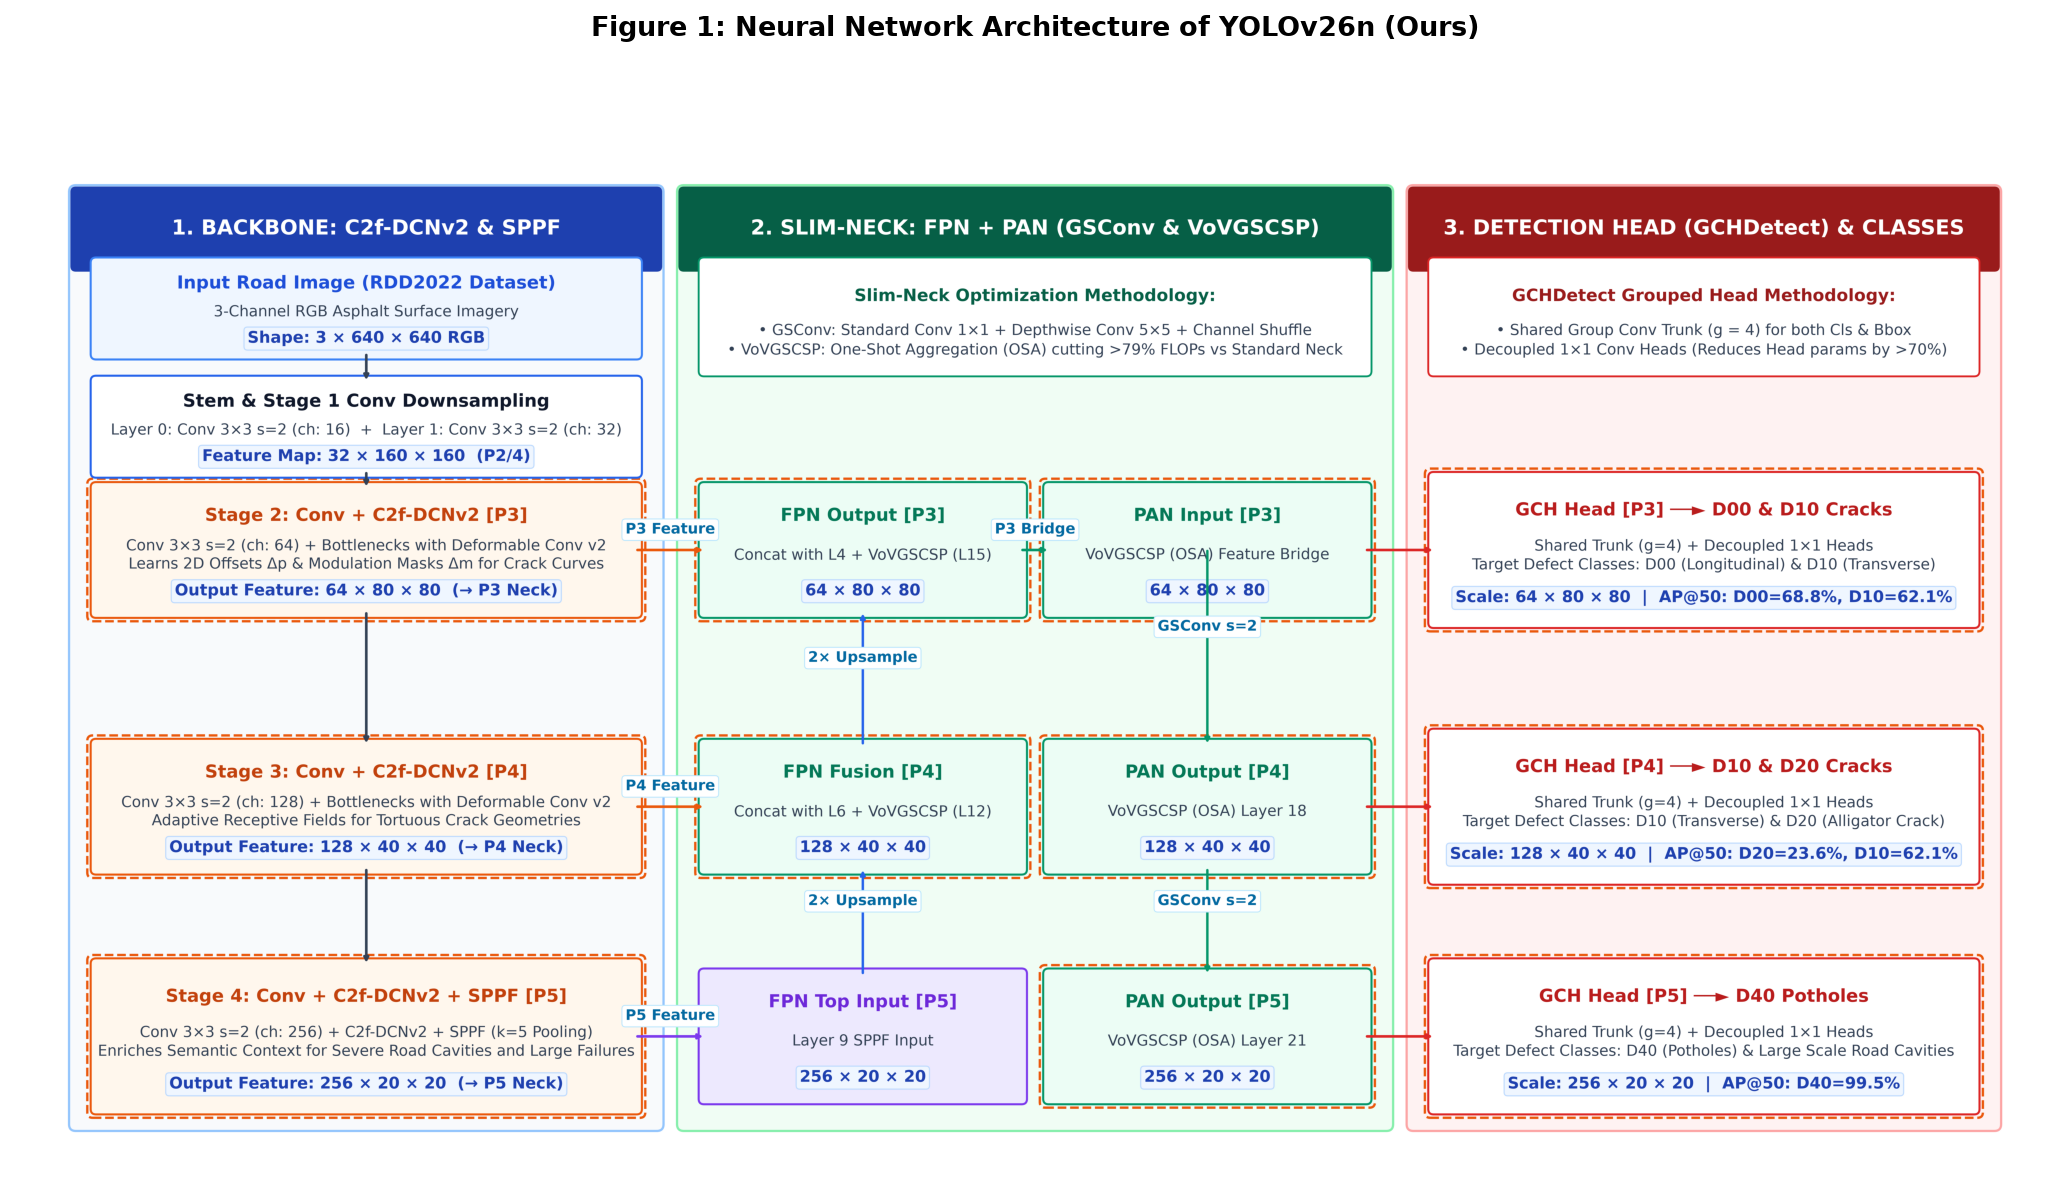

Successfully generated pipeline diagram: /Users/trietnguyen/Documents/AIL-RDD/fig/f2_pipeline_yolov26n.png


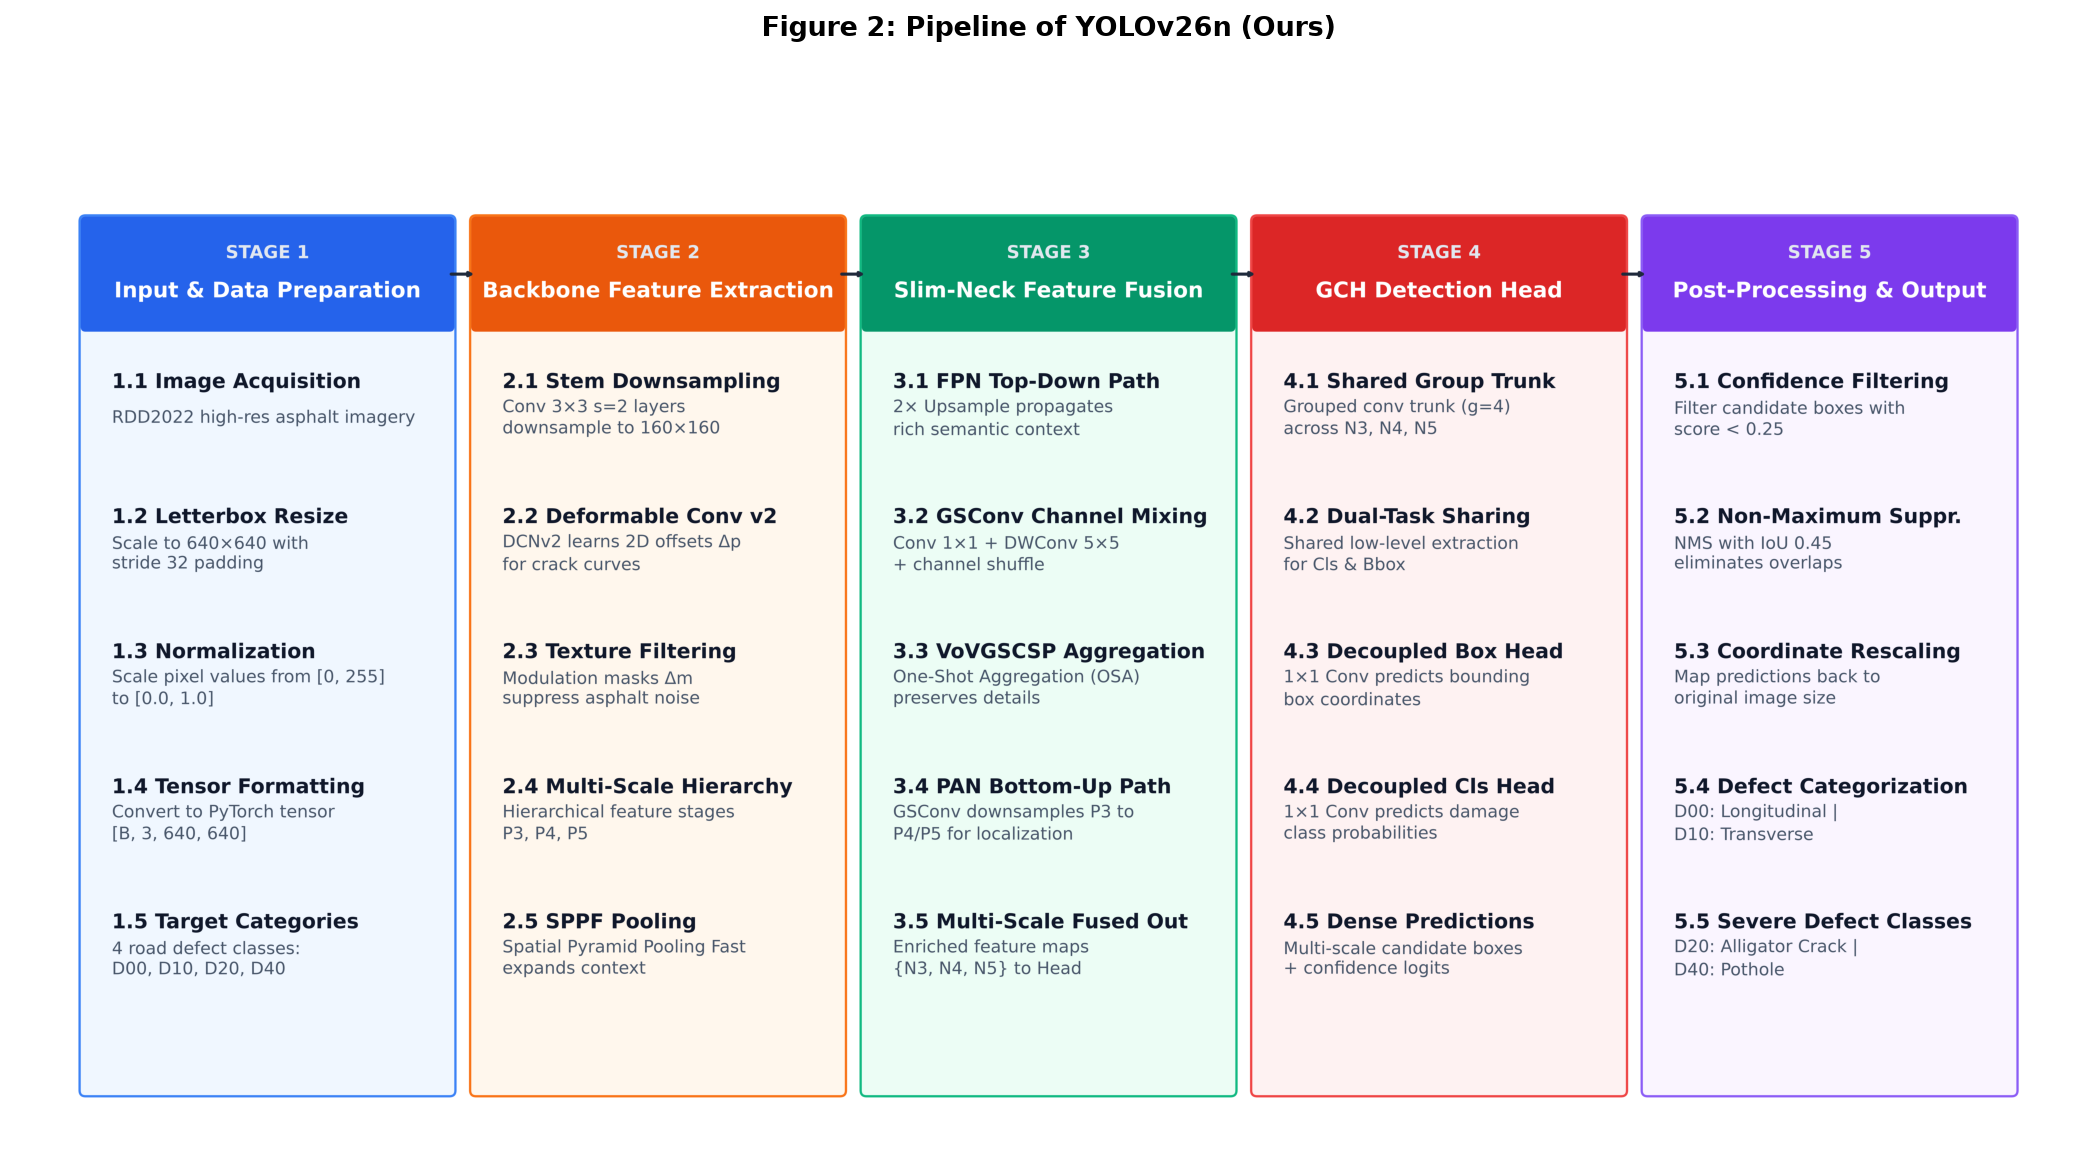

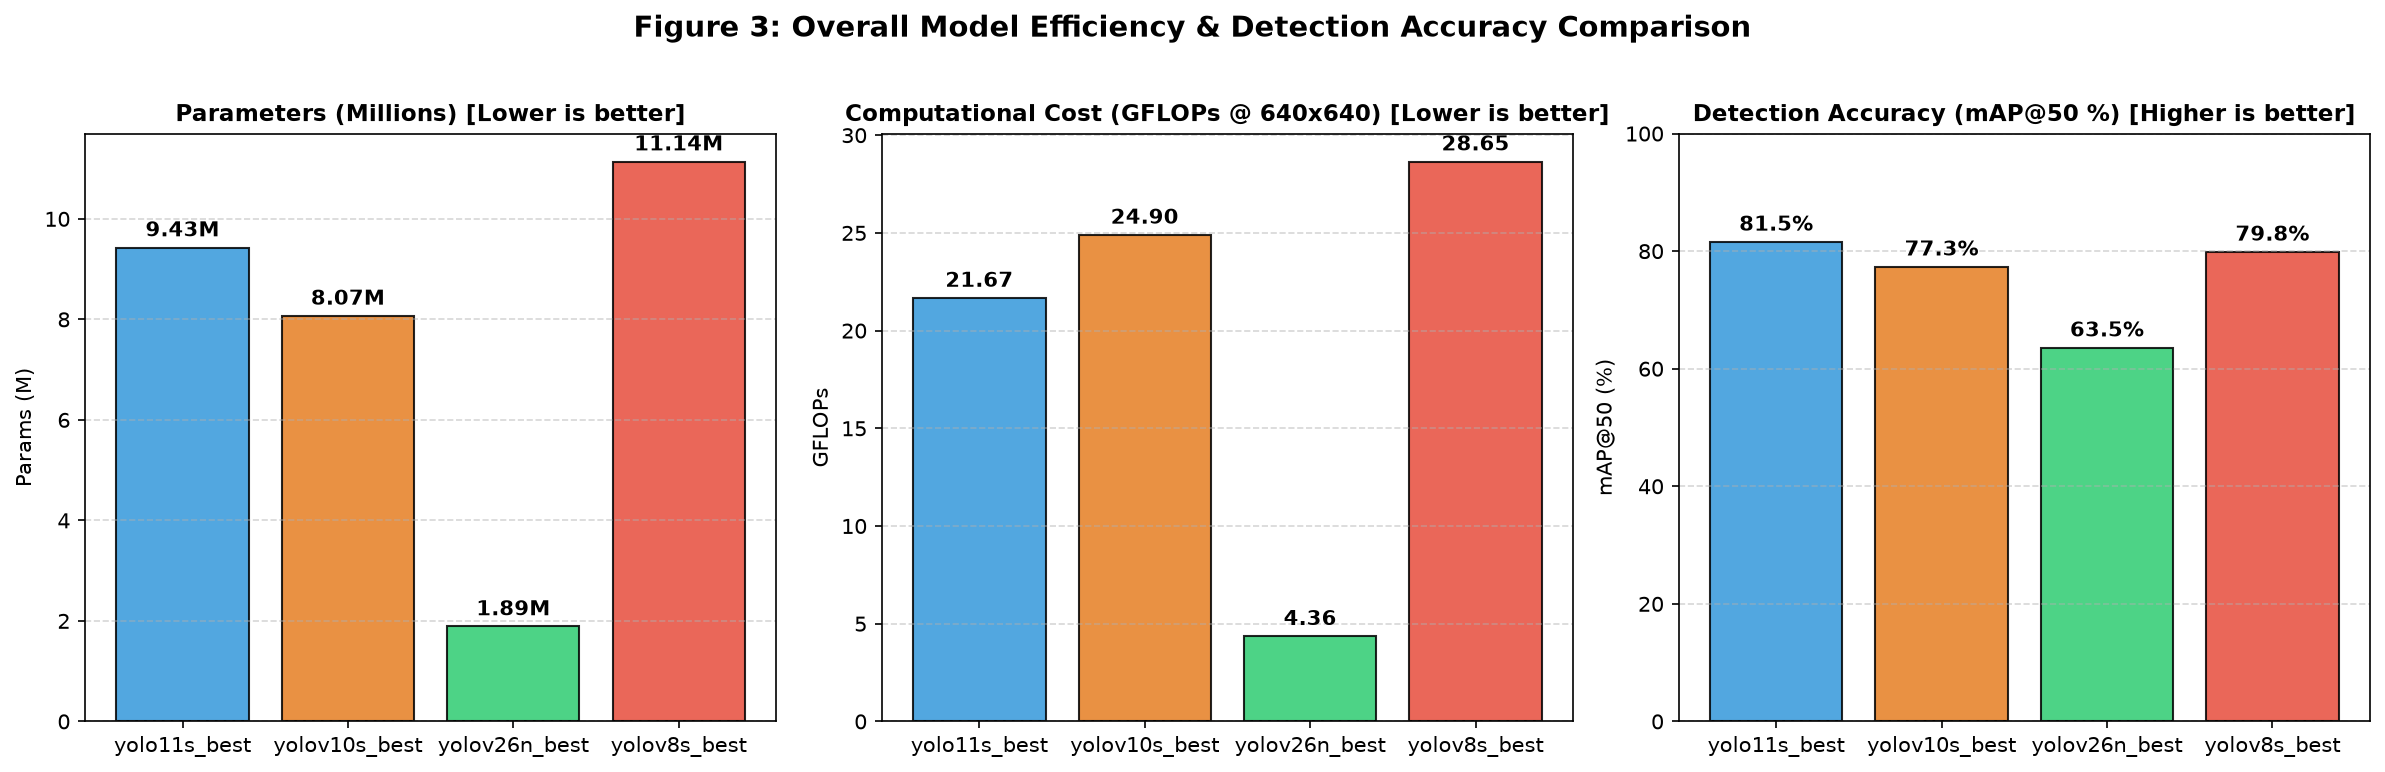

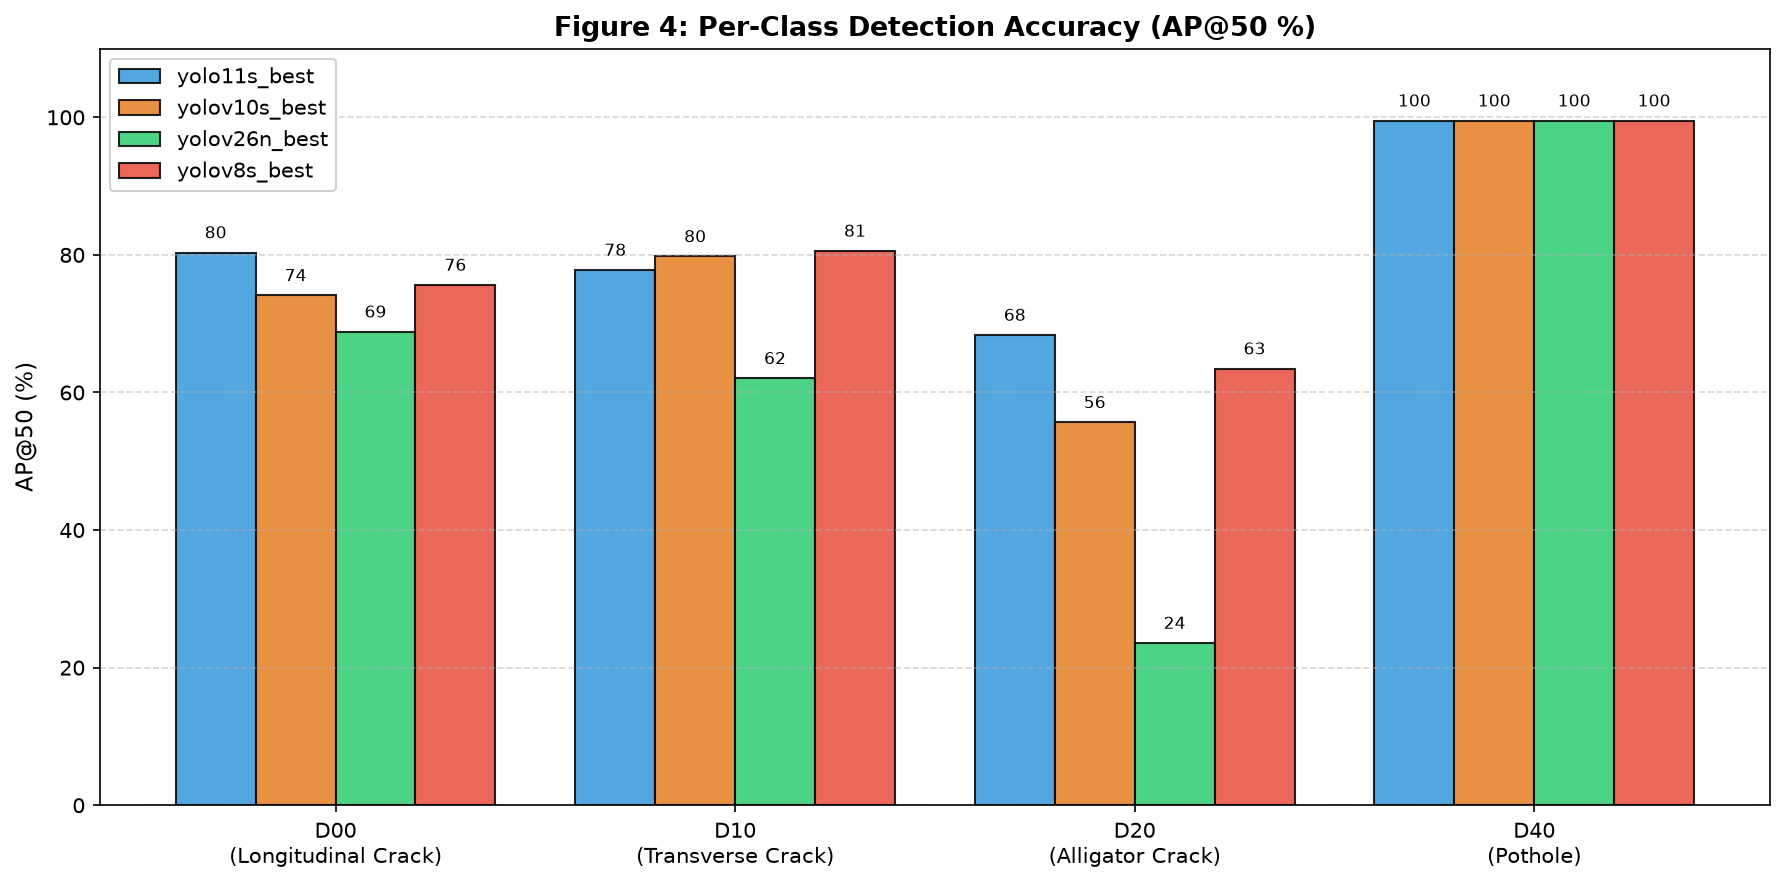

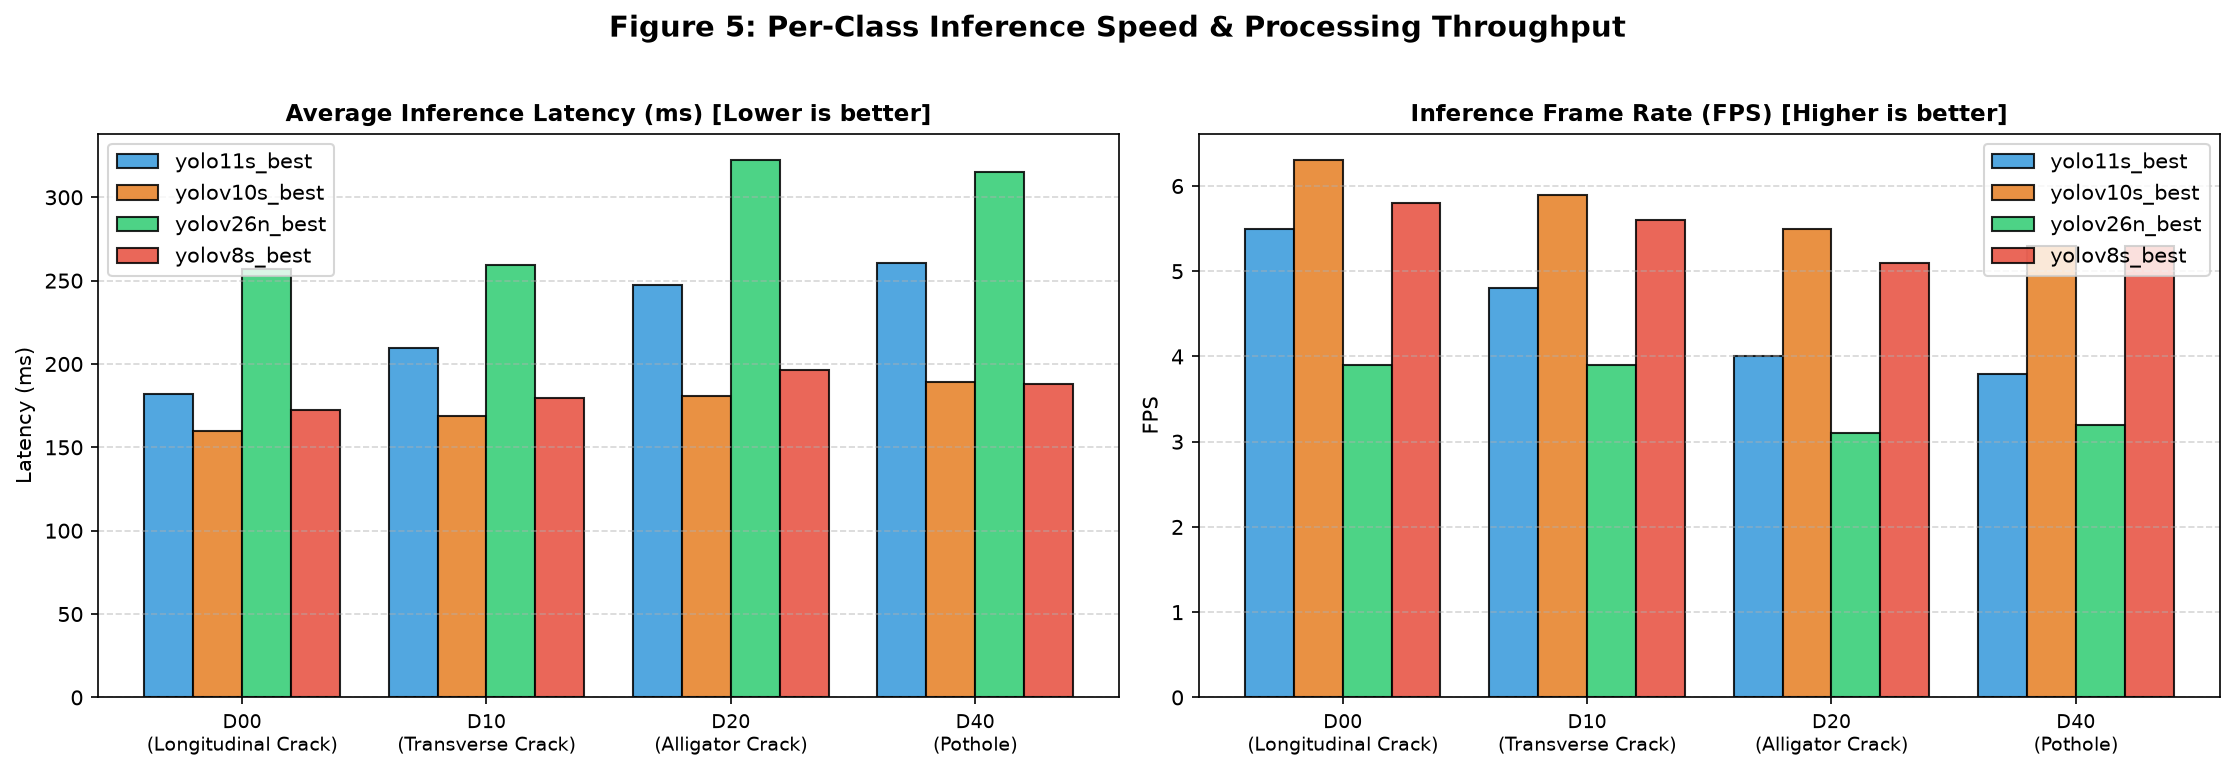

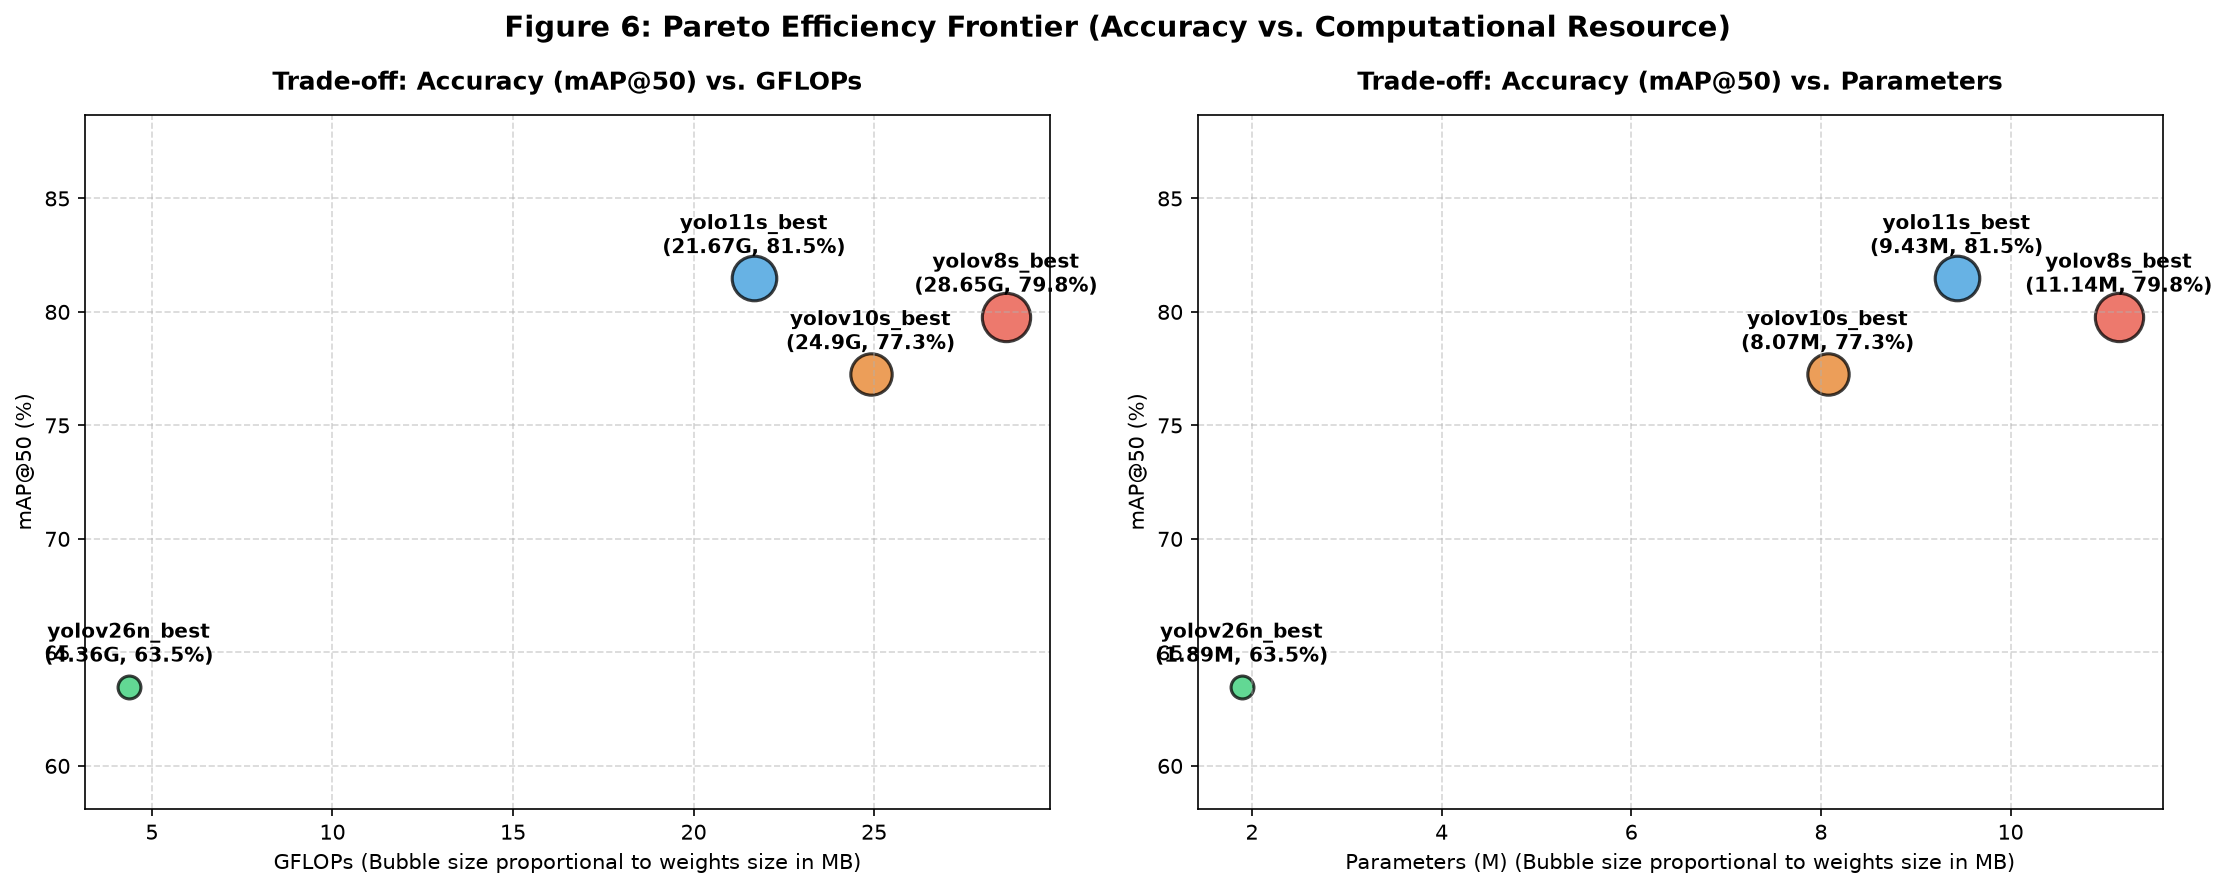

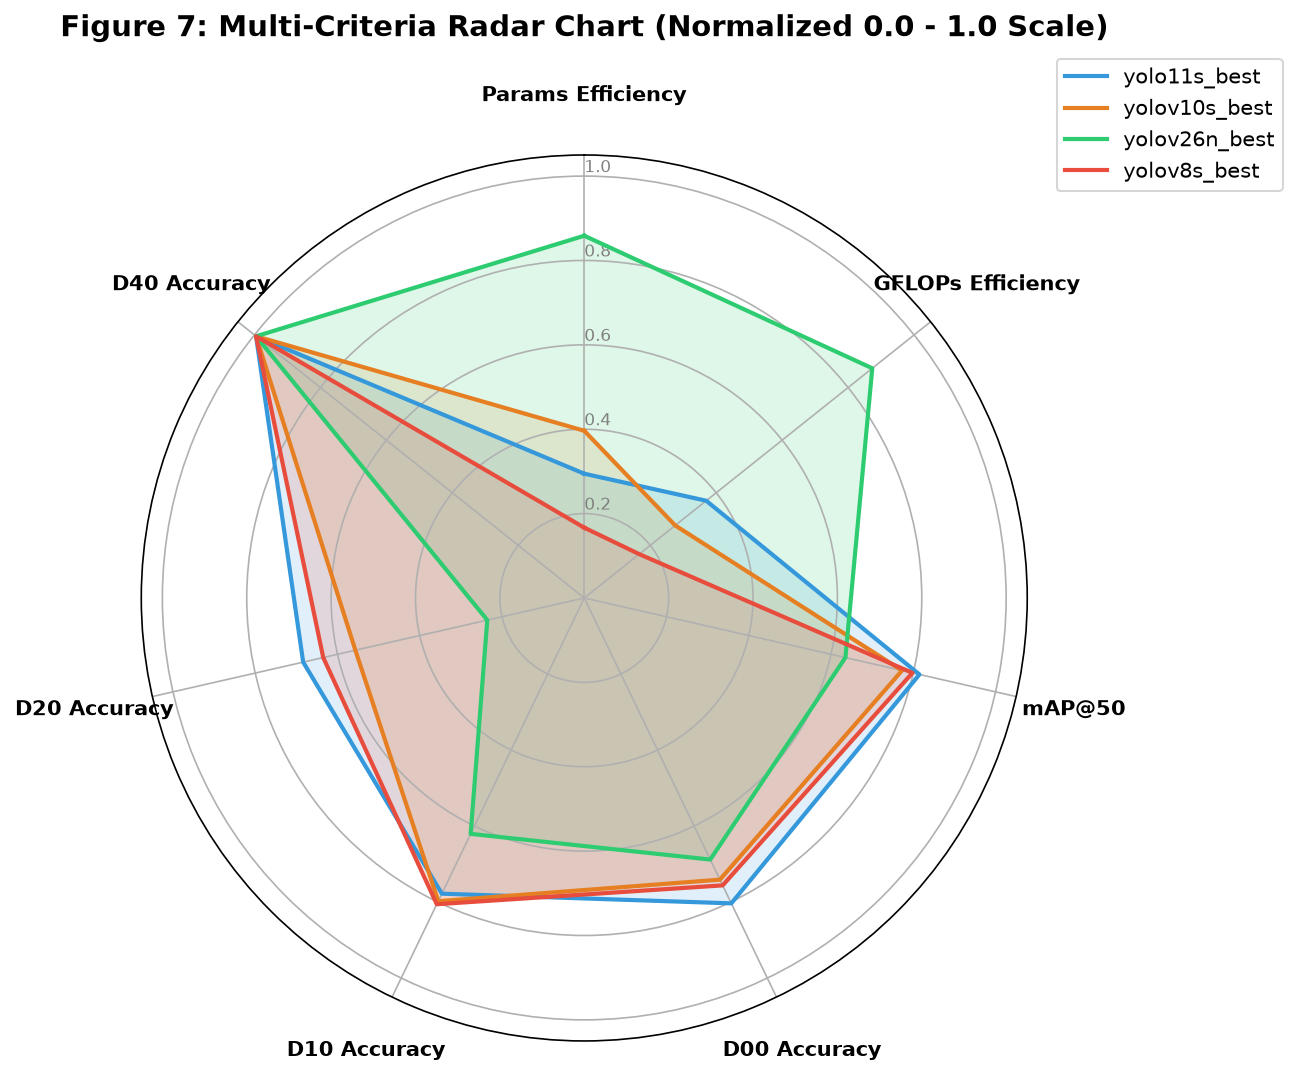

Saved 7 high-resolution visualization figures (f1 - f7) to: /Users/trietnguyen/Documents/AIL-RDD/fig


In [8]:
PLOTS_DIR = PROJECT_ROOT / 'fig'
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

if not combined_data:
    print('Warning: No benchmark data available for visualization.')
else:
    model_labels = [d['model_name'] for d in combined_data]
    palette = ['#3498db', '#e67e22', '#2ecc71', '#e74c3c', '#9b59b6', '#1abc9c']
    model_colors = [palette[i % len(palette)] for i in range(len(combined_data))]

    # -------------------------------------------------------------
    # GENERATE STREAMLINED ARCHITECTURE DIAGRAM (YOLOV26N)
    # -------------------------------------------------------------
    def generate_yolov26n_architecture(output_path):
        fig = plt.figure(figsize=(30, 16.5), dpi=300)
        ax = fig.add_axes([0, 0, 1, 1])
        ax.set_xlim(0, 30)
        ax.set_ylim(0, 16.5)
        ax.axis('off')
        ax.add_patch(patches.Rectangle((0, 0), 30, 16.5, facecolor='#FFFFFF'))


        # Section card background helper (+40% font: 15.5 -> 22pt)
        def draw_section_card(x, y, w, h, title, title_bg='#1E40AF', card_bg='#F8FAFC', border_color='#93C5FD'):
            ax.add_patch(patches.FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.10',
                                                facecolor=card_bg, edgecolor=border_color, linewidth=2.4, zorder=1))
            header_h = 1.10
            ax.add_patch(patches.FancyBboxPatch((x, y + h - header_h), w, header_h, boxstyle='round,pad=0.08',
                                                facecolor=title_bg, edgecolor='none', zorder=2))
            ax.text(x + w / 2, y + h - header_h / 2, title, fontsize=22.0, fontweight='bold',
                    color='#FFFFFF', ha='center', va='center', zorder=3)

        # Node drawing helper (+40% fonts: 13.5 -> 19pt, 11.5 -> 16pt, 12.0 -> 17pt)
        def draw_node(x, y, w, h, name, desc="", tensor="", bg='#FFFFFF', border='#2563EB', title_color='#0F172A', is_novel=False):
            if is_novel:
                ax.add_patch(patches.FancyBboxPatch((x - 0.05, y - 0.05), w + 0.1, h + 0.1, boxstyle='round,pad=0.08',
                                                    facecolor='none', edgecolor='#EA580C', linewidth=2.5, linestyle='--', zorder=3))
            ax.add_patch(patches.FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.08',
                                                facecolor=bg, edgecolor=border, linewidth=2.2, zorder=4))
            if tensor and desc:
                ax.text(x + w / 2, y + h * 0.77, name, fontsize=19.0, fontweight='bold', ha='center', va='center', color=title_color, zorder=5)
                ax.text(x + w / 2, y + h * 0.46, desc, fontsize=16.0, ha='center', va='center', color='#334155', linespacing=1.25, zorder=5)
                ax.text(x + w / 2, y + h * 0.17, tensor, fontsize=17.0, fontweight='bold', ha='center', va='center',
                        color='#1E40AF', bbox=dict(boxstyle='round,pad=0.22', facecolor='#EFF6FF', edgecolor='#BFDBFE', lw=1.2), zorder=5)
            elif desc:
                ax.text(x + w / 2, y + h * 0.70, name, fontsize=19.0, fontweight='bold', ha='center', va='center', color=title_color, zorder=5)
                ax.text(x + w / 2, y + h * 0.32, desc, fontsize=16.0, ha='center', va='center', color='#334155', linespacing=1.25, zorder=5)
            else:
                ax.text(x + w / 2, y + h * 0.50, name, fontsize=19.0, fontweight='bold', ha='center', va='center', color=title_color, zorder=5)

        # Arrow helper (+40% font: 11.0 -> 15.5pt)
        def draw_arrow(x1, y1, x2, y2, color='#334155', lw=2.8, label=""):
            ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                        arrowprops=dict(arrowstyle='->', lw=lw, color=color, shrinkA=1, shrinkB=1), zorder=7)
            if label:
                mid_x = (x1 + x2) / 2
                mid_y = (y1 + y2) / 2
                ax.text(mid_x, mid_y + 0.30, label, fontsize=15.5, fontweight='bold', ha='center', va='center',
                        color='#0369A1', bbox=dict(boxstyle='round,pad=0.24', facecolor='#FFFFFF', edgecolor='#BAE6FD', lw=1.0), zorder=8)

        # 3 Section boundaries across full width
        draw_section_card(0.8, 0.8, 8.6, 13.8, '1. BACKBONE: C2f-DCNv2 & SPPF', '#1E40AF', '#F8FAFC', '#93C5FD')
        draw_section_card(9.8, 0.8, 10.4, 13.8, '2. SLIM-NECK: FPN + PAN (GSConv & VoVGSCSP)', '#065F46', '#F0FDF4', '#86EFAC')
        draw_section_card(20.6, 0.8, 8.6, 13.8, '3. DETECTION HEAD (GCHDetect) & CLASSES', '#991B1B', '#FEF2F2', '#FCA5A5')

        # Parallel Y-tracks
        # Track P3: center = 9.30
        # Track P4: center = 5.50
        # Track P5: center = 2.10

        # -------------------------------------------------------------
        # 1. BACKBONE NODES
        # -------------------------------------------------------------
        bx, bw = 1.1, 8.0

        draw_node(bx, 12.20, bw, 1.35, 'Input Road Image (RDD2022 Dataset)',
                  '3-Channel RGB Asphalt Surface Imagery', 'Shape: 3 × 640 × 640 RGB',
                  bg='#EFF6FF', border='#3B82F6', title_color='#1D4ED8')
        draw_arrow(bx + bw / 2, 12.20, bx + bw / 2, 11.80, lw=2.8)

        draw_node(bx, 10.45, bw, 1.35, 'Stem & Stage 1 Conv Downsampling',
                  'Layer 0: Conv 3×3 s=2 (ch: 16)  +  Layer 1: Conv 3×3 s=2 (ch: 32)',
                  'Feature Map: 32 × 160 × 160  (P2/4)',
                  bg='#FFFFFF', border='#2563EB')
        draw_arrow(bx + bw / 2, 10.45, bx + bw / 2, 10.225, lw=2.8)

        # Stage 2: P3 (Center = 9.30, y = 8.375, h = 1.85)
        draw_node(bx, 8.375, bw, 1.85, 'Stage 2: Conv + C2f-DCNv2 [P3]',
                  'Conv 3×3 s=2 (ch: 64) + Bottlenecks with Deformable Conv v2\nLearns 2D Offsets Δp & Modulation Masks Δm for Crack Curves',
                  'Output Feature: 64 × 80 × 80  (→ P3 Neck)',
                  bg='#FFF7ED', border='#EA580C', title_color='#C2410C', is_novel=True)
        draw_arrow(bx + bw / 2, 8.375, bx + bw / 2, 6.425, lw=2.8)

        # Stage 3: P4 (Center = 5.50, y = 4.575, h = 1.85)
        draw_node(bx, 4.575, bw, 1.85, 'Stage 3: Conv + C2f-DCNv2 [P4]',
                  'Conv 3×3 s=2 (ch: 128) + Bottlenecks with Deformable Conv v2\nAdaptive Receptive Fields for Tortuous Crack Geometries',
                  'Output Feature: 128 × 40 × 40  (→ P4 Neck)',
                  bg='#FFF7ED', border='#EA580C', title_color='#C2410C', is_novel=True)
        draw_arrow(bx + bw / 2, 4.575, bx + bw / 2, 3.175, lw=2.8)

        # Stage 4: P5 (Center = 2.10, y = 1.025, h = 2.15)
        draw_node(bx, 1.025, bw, 2.15, 'Stage 4: Conv + C2f-DCNv2 + SPPF [P5]',
                  'Conv 3×3 s=2 (ch: 256) + C2f-DCNv2 + SPPF (k=5 Pooling)\nEnriches Semantic Context for Severe Road Cavities and Large Failures',
                  'Output Feature: 256 × 20 × 20  (→ P5 Neck)',
                  bg='#FFF7ED', border='#EA580C', title_color='#C2410C', is_novel=True)

        # -------------------------------------------------------------
        # 2. SLIM-NECK NODES (FPN + PAN)
        # -------------------------------------------------------------
        fnx, fnw = 10.1, 4.7   # FPN column
        pnx, pnw = 15.2, 4.7   # PAN column

        # Slim-Neck Top Method Box (+40% fonts: 13.0 -> 18pt, 11.5 -> 16pt)
        ax.add_patch(patches.FancyBboxPatch((10.1, 11.95), 9.8, 1.60, boxstyle='round,pad=0.08',
                                            facecolor='#FFFFFF', edgecolor='#059669', linewidth=2.0, zorder=4))
        ax.text(15.0, 13.05, 'Slim-Neck Optimization Methodology:',
                fontsize=18.0, fontweight='bold', ha='center', va='center', color='#065F46', zorder=6)
        ax.text(15.0, 12.40, '• GSConv: Standard Conv 1×1 + Depthwise Conv 5×5 + Channel Shuffle\n• VoVGSCSP: One-Shot Aggregation (OSA) cutting >79% FLOPs vs Standard Neck',
                fontsize=16.0, ha='center', va='center', color='#334155', linespacing=1.3, zorder=6)

        # Track P5 (Center = 2.10, y = 1.175, h = 1.85)
        draw_node(fnx, 1.175, fnw, 1.85, 'FPN Top Input [P5]',
                  'Layer 9 SPPF Input', '256 × 20 × 20',
                  bg='#EDE9FE', border='#7C3AED', title_color='#6D28D9')
        draw_arrow(bx + bw, 2.10, fnx, 2.10, color='#7C3AED', lw=2.8, label='P5 Feature')

        draw_node(pnx, 1.175, pnw, 1.85, 'PAN Output [P5]',
                  'VoVGSCSP (OSA) Layer 21', '256 × 20 × 20',
                  bg='#ECFDF5', border='#059669', title_color='#047857', is_novel=True)

        draw_arrow(fnx + fnw / 2, 3.025, fnx + fnw / 2, 4.575, color='#2563EB', lw=2.6, label='2× Upsample')

        # Track P4 (Center = 5.50, y = 4.575, h = 1.85)
        draw_node(fnx, 4.575, fnw, 1.85, 'FPN Fusion [P4]',
                  'Concat with L6 + VoVGSCSP (L12)', '128 × 40 × 40',
                  bg='#ECFDF5', border='#059669', title_color='#047857', is_novel=True)
        draw_arrow(bx + bw, 5.50, fnx, 5.50, color='#EA580C', lw=2.8, label='P4 Feature')

        draw_node(pnx, 4.575, pnw, 1.85, 'PAN Output [P4]',
                  'VoVGSCSP (OSA) Layer 18', '128 × 40 × 40',
                  bg='#ECFDF5', border='#059669', title_color='#047857', is_novel=True)

        draw_arrow(fnx + fnw / 2, 6.425, fnx + fnw / 2, 8.375, color='#2563EB', lw=2.6, label='2× Upsample')

        # Track P3 (Center = 9.30, y = 8.375, h = 1.85)
        draw_node(fnx, 8.375, fnw, 1.85, 'FPN Output [P3]',
                  'Concat with L4 + VoVGSCSP (L15)', '64 × 80 × 80',
                  bg='#ECFDF5', border='#059669', title_color='#047857', is_novel=True)
        draw_arrow(bx + bw, 9.30, fnx, 9.30, color='#EA580C', lw=2.8, label='P3 Feature')

        draw_node(pnx, 8.375, pnw, 1.85, 'PAN Input [P3]',
                  'VoVGSCSP (OSA) Feature Bridge', '64 × 80 × 80',
                  bg='#ECFDF5', border='#059669', title_color='#047857', is_novel=True)

        draw_arrow(fnx + fnw, 9.30, pnx, 9.30, color='#059669', lw=2.8, label='P3 Bridge')
        draw_arrow(pnx + pnw / 2, 9.30, pnx + pnw / 2, 6.425, color='#059669', lw=2.6, label='GSConv s=2')
        draw_arrow(pnx + pnw / 2, 4.575, pnx + pnw / 2, 3.025, color='#059669', lw=2.6, label='GSConv s=2')

        # -------------------------------------------------------------
        # 3. DETECTION HEAD & DAMAGE CLASSES
        # -------------------------------------------------------------
        hx, hw = 20.9, 8.0

        # GCHDetect Top Method Box (+40% fonts: 13.0 -> 18pt, 11.5 -> 16pt)
        ax.add_patch(patches.FancyBboxPatch((hx, 11.95), hw, 1.60, boxstyle='round,pad=0.08',
                                            facecolor='#FFFFFF', edgecolor='#DC2626', linewidth=2.0, zorder=4))
        ax.text(hx + hw / 2, 13.05, 'GCHDetect Grouped Head Methodology:',
                fontsize=18.0, fontweight='bold', ha='center', va='center', color='#991B1B', zorder=6)
        ax.text(hx + hw / 2, 12.40, '• Shared Group Conv Trunk (g = 4) for both Cls & Bbox\n• Decoupled 1×1 Conv Heads (Reduces Head params by >70%)',
                fontsize=16.0, ha='center', va='center', color='#334155', linespacing=1.3, zorder=6)

        # Track P3 Head (Center = 9.30, h = 2.15, y = 8.225)
        draw_node(hx, 8.225, hw, 2.15, 'GCH Head [P3] ──► D00 & D10 Cracks',
                  'Shared Trunk (g=4) + Decoupled 1×1 Heads\nTarget Defect Classes: D00 (Longitudinal) & D10 (Transverse)',
                  'Scale: 64 × 80 × 80  |  AP@50: D00=68.8%, D10=62.1%',
                  bg='#FFFFFF', border='#DC2626', title_color='#B91C1C', is_novel=True)
        draw_arrow(pnx + pnw, 9.30, hx, 9.30, color='#DC2626', lw=2.8)

        # Track P4 Head (Center = 5.50, h = 2.15, y = 4.425)
        draw_node(hx, 4.425, hw, 2.15, 'GCH Head [P4] ──► D10 & D20 Cracks',
                  'Shared Trunk (g=4) + Decoupled 1×1 Heads\nTarget Defect Classes: D10 (Transverse) & D20 (Alligator Crack)',
                  'Scale: 128 × 40 × 40  |  AP@50: D20=23.6%, D10=62.1%',
                  bg='#FFFFFF', border='#DC2626', title_color='#B91C1C', is_novel=True)
        draw_arrow(pnx + pnw, 5.50, hx, 5.50, color='#DC2626', lw=2.8)

        # Track P5 Head (Center = 2.10, h = 2.15, y = 1.025)
        draw_node(hx, 1.025, hw, 2.15, 'GCH Head [P5] ──► D40 Potholes',
                  'Shared Trunk (g=4) + Decoupled 1×1 Heads\nTarget Defect Classes: D40 (Potholes) & Large Scale Road Cavities',
                  'Scale: 256 × 20 × 20  |  AP@50: D40=99.5%',
                  bg='#FFFFFF', border='#DC2626', title_color='#B91C1C', is_novel=True)
        draw_arrow(pnx + pnw, 2.10, hx, 2.10, color='#DC2626', lw=2.8)

        Path(output_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(output_path, dpi=300, bbox_inches='tight', pad_inches=0.1)
        plt.close(fig)
        print(f'Successfully generated architecture diagram: {output_path}')


    def generate_yolov26n_pipeline(output_path):
        fig = plt.figure(figsize=(35, 18.5), dpi=300)
        ax = fig.add_axes([0, 0, 1, 1])
        ax.set_xlim(0, 35)
        ax.set_ylim(0, 18.5)
        ax.axis('off')
        ax.add_patch(patches.Rectangle((0, 0), 35, 18.5, facecolor='#FFFFFF'))


        # 5 Sequential Stages - Exact user content preserved with neat 2-line wraps
        stages = [
            {
                'num': 'STAGE 1',
                'name': 'Input & Data Preparation',
                'color': '#2563EB',
                'card_bg': '#F0F7FF',
                'border': '#3B82F6',
                'steps': [
                    ('1.1 Image Acquisition', 'RDD2022 high-res asphalt imagery'),
                    ('1.2 Letterbox Resize', 'Scale to 640×640 with\nstride 32 padding'),
                    ('1.3 Normalization', 'Scale pixel values from [0, 255]\nto [0.0, 1.0]'),
                    ('1.4 Tensor Formatting', 'Convert to PyTorch tensor\n[B, 3, 640, 640]'),
                    ('1.5 Target Categories', '4 road defect classes:\nD00, D10, D20, D40')
                ]
            },
            {
                'num': 'STAGE 2',
                'name': 'Backbone Feature Extraction',
                'color': '#EA580C',
                'card_bg': '#FFF7ED',
                'border': '#F97316',
                'steps': [
                    ('2.1 Stem Downsampling', 'Conv 3×3 s=2 layers\ndownsample to 160×160'),
                    ('2.2 Deformable Conv v2', 'DCNv2 learns 2D offsets Δp\nfor crack curves'),
                    ('2.3 Texture Filtering', 'Modulation masks Δm\nsuppress asphalt noise'),
                    ('2.4 Multi-Scale Hierarchy', 'Hierarchical feature stages\nP3, P4, P5'),
                    ('2.5 SPPF Pooling', 'Spatial Pyramid Pooling Fast\nexpands context')
                ]
            },
            {
                'num': 'STAGE 3',
                'name': 'Slim-Neck Feature Fusion',
                'color': '#059669',
                'card_bg': '#ECFDF5',
                'border': '#10B981',
                'steps': [
                    ('3.1 FPN Top-Down Path', '2× Upsample propagates\nrich semantic context'),
                    ('3.2 GSConv Channel Mixing', 'Conv 1×1 + DWConv 5×5\n+ channel shuffle'),
                    ('3.3 VoVGSCSP Aggregation', 'One-Shot Aggregation (OSA)\npreserves details'),
                    ('3.4 PAN Bottom-Up Path', 'GSConv downsamples P3 to\nP4/P5 for localization'),
                    ('3.5 Multi-Scale Fused Out', 'Enriched feature maps\n{N3, N4, N5} to Head')
                ]
            },
            {
                'num': 'STAGE 4',
                'name': 'GCH Detection Head',
                'color': '#DC2626',
                'card_bg': '#FEF2F2',
                'border': '#EF4444',
                'steps': [
                    ('4.1 Shared Group Trunk', 'Grouped conv trunk (g=4)\nacross N3, N4, N5'),
                    ('4.2 Dual-Task Sharing', 'Shared low-level extraction\nfor Cls & Bbox'),
                    ('4.3 Decoupled Box Head', '1×1 Conv predicts bounding\nbox coordinates'),
                    ('4.4 Decoupled Cls Head', '1×1 Conv predicts damage\nclass probabilities'),
                    ('4.5 Dense Predictions', 'Multi-scale candidate boxes\n+ confidence logits')
                ]
            },
            {
                'num': 'STAGE 5',
                'name': 'Post-Processing & Output',
                'color': '#7C3AED',
                'card_bg': '#FAF5FF',
                'border': '#8B5CF6',
                'steps': [
                    ('5.1 Confidence Filtering', 'Filter candidate boxes with\nscore < 0.25'),
                    ('5.2 Non-Maximum Suppr.', 'NMS with IoU 0.45\neliminates overlaps'),
                    ('5.3 Coordinate Rescaling', 'Map predictions back to\noriginal image size'),
                    ('5.4 Defect Categorization', 'D00: Longitudinal |\nD10: Transverse'),
                    ('5.5 Severe Defect Classes', 'D20: Alligator Crack |\nD40: Pothole')
                ]
            }
        ]

        card_w = 6.2
        card_h = 14.8
        start_x = 1.1
        card_spacing = 0.45
        card_y = 1.0

        for idx, stage in enumerate(stages):
            cx = start_x + idx * (card_w + card_spacing)

            # Stage Card Boundary
            ax.add_patch(patches.FancyBboxPatch((cx, card_y), card_w, card_h, boxstyle='round,pad=0.10',
                                                facecolor=stage['card_bg'], edgecolor=stage['border'], linewidth=2.8, zorder=2))

            # Two-line clean Stage Header
            hh = 1.80
            ax.add_patch(patches.FancyBboxPatch((cx, card_y + card_h - hh), card_w, hh, boxstyle='round,pad=0.08',
                                                facecolor=stage['color'], edgecolor='none', zorder=3))
            ax.text(cx + card_w / 2, card_y + card_h - 0.55, stage['num'],
                    fontsize=22.0, fontweight='bold', color='#E2E8F0', ha='center', va='center', zorder=4)
            ax.text(cx + card_w / 2, card_y + card_h - 1.20, stage['name'],
                    fontsize=26.5, fontweight='bold', color='#FFFFFF', ha='center', va='center', zorder=4)

            # 5 Step Rows per Stage
            step_y_start = card_y + card_h - hh - 0.95
            y_step = 2.30

            for s_idx, (s_title, s_desc) in enumerate(stage['steps']):
                curr_y = step_y_start - s_idx * y_step
                ax.text(cx + 0.45, curr_y, s_title, fontsize=25.0, fontweight='bold', color='#0F172A', ha='left', va='center', zorder=4)
                ax.text(cx + 0.45, curr_y - 0.60, s_desc, fontsize=21.0, color='#475569', ha='left', va='center', linespacing=1.24, zorder=4)

            # Inter-stage connector arrows between header bars
            if idx < len(stages) - 1:
                arrow_y = card_y + card_h - hh / 2
                ax.annotate('', xy=(cx + card_w + card_spacing, arrow_y),
                            xytext=(cx + card_w, arrow_y),
                            arrowprops=dict(arrowstyle='->', lw=3.8, color='#1E293B', shrinkA=2, shrinkB=2), zorder=5)

        Path(output_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(output_path, dpi=300, bbox_inches='tight', pad_inches=0.1)
        plt.close(fig)
        print(f'Successfully generated pipeline diagram: {output_path}')

    # FIGURE 1: YOLOV26N NEURAL NETWORK ARCHITECTURE
    # -------------------------------------------------------------
    arch_file = PLOTS_DIR / 'f1_architecture_yolov26n.png'
    generate_yolov26n_architecture(arch_file)
    img_arch = mpimg.imread(str(arch_file))
    fig_arch_show = plt.figure(figsize=(15, 8.1), dpi=150)
    plt.imshow(img_arch)
    plt.axis('off')
    plt.title('Figure 1: Neural Network Architecture of YOLOv26n (Ours)', fontsize=13, fontweight='bold', pad=10)
    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # FIGURE 2: YOLOV26N INFERENCE & EVALUATION PIPELINE
    # -------------------------------------------------------------
    pipe_file = PLOTS_DIR / 'f2_pipeline_yolov26n.png'
    generate_yolov26n_pipeline(pipe_file)
    img_pipe = mpimg.imread(str(pipe_file))
    fig_pipe_show = plt.figure(figsize=(15, 7.9), dpi=150)
    plt.imshow(img_pipe)
    plt.axis('off')
    plt.title('Figure 2: Pipeline of YOLOv26n (Ours)', fontsize=13, fontweight='bold', pad=10)
    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # FIGURE 3: CORE METRICS COMPARISON
    # -------------------------------------------------------------
    fig_core, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=150)
    max_param = max([d['params_m'] for d in combined_data], default=1.0) or 1.0
    max_flop = max([d['gflops'] for d in combined_data], default=1.0) or 1.0

    # Parameters
    axes[0].bar(model_labels, [d['params_m'] for d in combined_data], color=model_colors, edgecolor='black', alpha=0.85)
    axes[0].set_title('Parameters (Millions) [Lower is better]', fontsize=11, fontweight='bold')
    axes[0].set_ylabel('Params (M)')
    axes[0].grid(axis='y', linestyle='--', alpha=0.5)
    for i, v in enumerate([d['params_m'] for d in combined_data]):
        axes[0].text(i, v + max_param * 0.02, f'{v:.2f}M', ha='center', fontsize=10, fontweight='bold')

    # GFLOPs
    axes[1].bar(model_labels, [d['gflops'] for d in combined_data], color=model_colors, edgecolor='black', alpha=0.85)
    axes[1].set_title('Computational Cost (GFLOPs @ 640x640) [Lower is better]', fontsize=11, fontweight='bold')
    axes[1].set_ylabel('GFLOPs')
    axes[1].grid(axis='y', linestyle='--', alpha=0.5)
    for i, v in enumerate([d['gflops'] for d in combined_data]):
        axes[1].text(i, v + max_flop * 0.02, f'{v:.2f}', ha='center', fontsize=10, fontweight='bold')

    # mAP@50
    axes[2].bar(model_labels, [d['map50'] for d in combined_data], color=model_colors, edgecolor='black', alpha=0.85)
    axes[2].set_title('Detection Accuracy (mAP@50 %) [Higher is better]', fontsize=11, fontweight='bold')
    axes[2].set_ylabel('mAP@50 (%)')
    axes[2].set_ylim(0, 100)
    axes[2].grid(axis='y', linestyle='--', alpha=0.5)
    for i, v in enumerate([d['map50'] for d in combined_data]):
        axes[2].text(i, v + 2, f'{v:.1f}%', ha='center', fontsize=10, fontweight='bold')

    plt.suptitle('Figure 3: Overall Model Efficiency & Detection Accuracy Comparison', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    fig_core.savefig(PLOTS_DIR / 'f3_core_metrics.png', bbox_inches='tight', dpi=300)
    plt.show()

    # -------------------------------------------------------------
    # FIGURE 4: PER-CLASS DETECTION ACCURACY (AP@50 %)
    # -------------------------------------------------------------
    fig_ap = plt.figure(figsize=(12, 6), dpi=150)
    x = np.arange(len(CLASS_NAMES))
    width = 0.8 / max(1, len(combined_data))

    for idx, d in enumerate(combined_data):
        ap_vals = [d['ap50_per_class'].get(c, 0.0) for c in CLASS_NAMES]
        offset = (idx - (len(combined_data) - 1) / 2) * width
        bars = plt.bar(x + offset, ap_vals, width, label=d['model_name'], color=model_colors[idx], edgecolor='black', alpha=0.85)
        for bar in bars:
            h = bar.get_height()
            if h > 0:
                plt.text(bar.get_x() + bar.get_width() / 2, h + 1.5, f'{h:.0f}', ha='center', va='bottom', fontsize=8)

    plt.title('Figure 4: Per-Class Detection Accuracy (AP@50 %)', fontsize=13, fontweight='bold')
    plt.xticks(x, [f'{c}\n({CLASS_LABELS[c]})' for c in CLASS_NAMES], fontsize=10)
    plt.ylabel('AP@50 (%)', fontsize=11)
    plt.ylim(0, 110)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.legend(frameon=True, facecolor='white', framealpha=0.9)
    plt.tight_layout()
    fig_ap.savefig(PLOTS_DIR / 'f4_per_class_ap.png', bbox_inches='tight', dpi=300)
    plt.show()

    # -------------------------------------------------------------
    # FIGURE 5: PER-CLASS INFERENCE SPEED & THROUGHPUT
    # -------------------------------------------------------------
    fig_spd, (ax_lat, ax_fps) = plt.subplots(1, 2, figsize=(15, 5), dpi=150)

    for idx, d in enumerate(combined_data):
        sp = d['speed_per_class']
        lat_vals = [sp.get(c, {}).get('latency_ms', 0.0) for c in CLASS_NAMES]
        fps_vals = [sp.get(c, {}).get('fps', 0.0) for c in CLASS_NAMES]
        offset = (idx - (len(combined_data) - 1) / 2) * width
        ax_lat.bar(x + offset, lat_vals, width, label=d['model_name'], color=model_colors[idx], edgecolor='black', alpha=0.85)
        ax_fps.bar(x + offset, fps_vals, width, label=d['model_name'], color=model_colors[idx], edgecolor='black', alpha=0.85)

    ax_lat.set_title('Average Inference Latency (ms) [Lower is better]', fontsize=11, fontweight='bold')
    ax_lat.set_xticks(x)
    ax_lat.set_xticklabels([f'{c}\n({CLASS_LABELS[c]})' for c in CLASS_NAMES], fontsize=9)
    ax_lat.set_ylabel('Latency (ms)')
    ax_lat.grid(axis='y', linestyle='--', alpha=0.5)
    ax_lat.legend()

    ax_fps.set_title('Inference Frame Rate (FPS) [Higher is better]', fontsize=11, fontweight='bold')
    ax_fps.set_xticks(x)
    ax_fps.set_xticklabels([f'{c}\n({CLASS_LABELS[c]})' for c in CLASS_NAMES], fontsize=9)
    ax_fps.set_ylabel('FPS')
    ax_fps.grid(axis='y', linestyle='--', alpha=0.5)
    ax_fps.legend()

    plt.suptitle('Figure 5: Per-Class Inference Speed & Processing Throughput', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    fig_spd.savefig(PLOTS_DIR / 'f5_speed_comparison.png', bbox_inches='tight', dpi=300)
    plt.show()

    # -------------------------------------------------------------
    # FIGURE 6: PARETO EFFICIENCY FRONTIER
    # -------------------------------------------------------------
    fig_pareto, (ax_p1, ax_p2) = plt.subplots(1, 2, figsize=(15, 6), dpi=150)
    all_map = [d['map50'] for d in combined_data]
    min_m = min(all_map) if all_map else 0.0
    max_m = max(all_map) if all_map else 100.0
    y_span = max(6.0, max_m - min_m)

    for idx, d in enumerate(combined_data):
        s = max(120.0, d['size_mb'] * 25.0)
        ax_p1.scatter(d['gflops'], d['map50'], s=s, color=model_colors[idx], alpha=0.75, edgecolors='black', linewidth=1.5)
        ax_p1.annotate(f"{d['model_name']}\n({d['gflops']}G, {d['map50']:.1f}%)",
                       (d['gflops'], d['map50']), textcoords='offset points', xytext=(0, 12), ha='center', fontsize=9.5, fontweight='bold')

        ax_p2.scatter(d['params_m'], d['map50'], s=s, color=model_colors[idx], alpha=0.75, edgecolors='black', linewidth=1.5)
        ax_p2.annotate(f"{d['model_name']}\n({d['params_m']}M, {d['map50']:.1f}%)",
                       (d['params_m'], d['map50']), textcoords='offset points', xytext=(0, 12), ha='center', fontsize=9.5, fontweight='bold')

    ax_p1.set_ylim(max(0.0, min_m - y_span * 0.3), min(100.0, max_m + y_span * 0.4))
    ax_p2.set_ylim(max(0.0, min_m - y_span * 0.3), min(100.0, max_m + y_span * 0.4))
    ax_p1.set_title('Trade-off: Accuracy (mAP@50) vs. GFLOPs', fontsize=12, fontweight='bold', pad=12)
    ax_p1.set_xlabel('GFLOPs (Bubble size proportional to weights size in MB)', fontsize=10)
    ax_p1.set_ylabel('mAP@50 (%)', fontsize=10)
    ax_p1.grid(True, linestyle='--', alpha=0.5)

    ax_p2.set_title('Trade-off: Accuracy (mAP@50) vs. Parameters', fontsize=12, fontweight='bold', pad=12)
    ax_p2.set_xlabel('Parameters (M) (Bubble size proportional to weights size in MB)', fontsize=10)
    ax_p2.set_ylabel('mAP@50 (%)', fontsize=10)
    ax_p2.grid(True, linestyle='--', alpha=0.5)

    plt.suptitle('Figure 6: Pareto Efficiency Frontier (Accuracy vs. Computational Resource)', fontsize=14, fontweight='bold', y=0.98)
    plt.tight_layout()
    fig_pareto.savefig(PLOTS_DIR / 'f6_pareto_tradeoff.png', bbox_inches='tight', dpi=300)
    plt.show()

    # -------------------------------------------------------------
    # FIGURE 7: MULTI-DIMENSIONAL RADAR EVALUATION
    # -------------------------------------------------------------
    radar_categories = ['Params Efficiency', 'GFLOPs Efficiency', 'mAP@50', 'D00 Accuracy', 'D10 Accuracy', 'D20 Accuracy', 'D40 Accuracy']
    N = len(radar_categories)
    angles = [n / float(N) * 2 * np.pi for n in range(N)]
    angles += angles[:1]

    fig_radar, ax_r = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True), dpi=150)

    for idx, d in enumerate(combined_data):
        p_eff = 1.0 - (d['params_m'] / (max_param * 1.2))
        g_eff = 1.0 - (d['gflops'] / (max_flop * 1.2))
        m50_norm = d['map50'] / 100.0
        d00_norm = d['ap50_per_class'].get('D00', 0.0) / 100.0
        d10_norm = d['ap50_per_class'].get('D10', 0.0) / 100.0
        d20_norm = d['ap50_per_class'].get('D20', 0.0) / 100.0
        d40_norm = d['ap50_per_class'].get('D40', 0.0) / 100.0

        values = [p_eff, g_eff, m50_norm, d00_norm, d10_norm, d20_norm, d40_norm]
        values += values[:1]
        ax_r.plot(angles, values, linewidth=2, linestyle='solid', label=d['model_name'], color=model_colors[idx])
        ax_r.fill(angles, values, color=model_colors[idx], alpha=0.15)

    ax_r.set_theta_offset(np.pi / 2)
    ax_r.set_theta_direction(-1)
    ax_r.tick_params(pad=18)
    plt.xticks(angles[:-1], radar_categories, fontsize=10, fontweight='bold')
    ax_r.set_rlabel_position(0)
    plt.yticks([0.2, 0.4, 0.6, 0.8, 1.0], ['0.2', '0.4', '0.6', '0.8', '1.0'], color='grey', size=8)
    plt.ylim(0, 1.05)
    plt.title('Figure 7: Multi-Criteria Radar Chart (Normalized 0.0 - 1.0 Scale)', fontsize=14, fontweight='bold', y=1.12)
    plt.legend(loc='upper right', bbox_to_anchor=(1.30, 1.12), fontsize=10)
    plt.tight_layout()
    fig_radar.savefig(PLOTS_DIR / 'f7_radar_chart.png', bbox_inches='tight', dpi=300)
    plt.show()
    print(f'Saved 7 high-resolution visualization figures (f1 - f7) to: {PLOTS_DIR}')


## 5. Summary & Export


In [9]:
print('=' * 115)
print('ROAD DAMAGE DETECTION (RDD) BENCHMARK SUMMARY TABLE')
print('=' * 115)
header = f"{'Model':<16} | {'Params (M)':<10} | {'GFLOPs':<8} | {'mAP@50 (%)':<11} | {'D00 (%)':<8} | {'D10 (%)':<8} | {'D20 (%)':<8} | {'D40 (%)':<8} | {'Latency':<8} | {'FPS':<6}"
print(header)
print('-' * 115)
for d in combined_data:
    pc = d['ap50_per_class']
    row_str = (
        f"{d['model_name']:<16} | "
        f"{d['params_m']:>10.2f} | "
        f"{d['gflops']:>8.2f} | "
        f"{d['map50']:>11.2f} | "
        f"{pc.get('D00', 0.0):>8.2f} | "
        f"{pc.get('D10', 0.0):>8.2f} | "
        f"{pc.get('D20', 0.0):>8.2f} | "
        f"{pc.get('D40', 0.0):>8.2f} | "
        f"{d['avg_latency_ms']:>6.1f}ms | "
        f"{d['avg_fps']:>5.1f}"
    )
    print(row_str)
print('=' * 115)

# Export CSV file
csv_path = (PROJECT_ROOT / 'benchmark' / 'benchmark_results.csv') if (PROJECT_ROOT / 'benchmark').exists() else (PROJECT_ROOT / 'benchmark_results.csv')
fieldnames = [
    'model_name', 'params_m', 'gflops', 'size_mb', 'map50', 'map50_95', 'precision', 'recall',
    'D00_ap50', 'D10_ap50', 'D20_ap50', 'D40_ap50', 'avg_latency_ms', 'avg_fps'
]
with open(csv_path, 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    for d in combined_data:
        pc = d['ap50_per_class']
        writer.writerow({
            'model_name': d['model_name'],
            'params_m': d['params_m'],
            'gflops': d['gflops'],
            'size_mb': d['size_mb'],
            'map50': d['map50'],
            'map50_95': d['map50_95'],
            'precision': d['precision'],
            'recall': d['recall'],
            'D00_ap50': pc.get('D00', 0.0),
            'D10_ap50': pc.get('D10', 0.0),
            'D20_ap50': pc.get('D20', 0.0),
            'D40_ap50': pc.get('D40', 0.0),
            'avg_latency_ms': d['avg_latency_ms'],
            'avg_fps': d['avg_fps'],
        })
print(f'Saved benchmark results to CSV: {csv_path}')

# Export JSON file
json_path = (PROJECT_ROOT / 'benchmark' / 'benchmark_results.json') if (PROJECT_ROOT / 'benchmark').exists() else (PROJECT_ROOT / 'benchmark_results.json')
with open(json_path, 'w', encoding='utf-8') as f:
    json.dump(combined_data, f, indent=2, ensure_ascii=False)
print(f'Saved detailed results to JSON: {json_path}')


ROAD DAMAGE DETECTION (RDD) BENCHMARK SUMMARY TABLE
Model            | Params (M) | GFLOPs   | mAP@50 (%)  | D00 (%)  | D10 (%)  | D20 (%)  | D40 (%)  | Latency  | FPS   
-------------------------------------------------------------------------------------------------------------------
yolo11s_best     |       9.43 |    21.67 |       81.49 |    80.34 |    77.80 |    68.34 |    99.50 |  288.2ms |   3.5
yolov10s_best    |       8.07 |    24.90 |       77.26 |    74.11 |    79.77 |    55.65 |    99.50 |  222.3ms |   4.5
yolov26n_best    |       1.89 |     4.36 |       63.49 |    68.82 |    62.06 |    23.58 |    99.50 |  272.8ms |   3.7
yolov8s_best     |      11.14 |    28.65 |       79.79 |    75.61 |    80.57 |    63.46 |    99.50 |  253.4ms |   3.9
Saved benchmark results to CSV: /Users/trietnguyen/Documents/AIL-RDD/benchmark/benchmark_results.csv
Saved detailed results to JSON: /Users/trietnguyen/Documents/AIL-RDD/benchmark/benchmark_results.json
